1. Познакомьтесь с данными.
2. Осуществите предобработку данных.
    - 2.1 Приведите заголовки к удобному виду.
    - 2.2 Проверьте типы данных.
    - 2.3 Обработайте пропуски.
    - 2.4 Проверьте наличие дубликатов.
    - 2.5 Исключите нулевые значения в выручке для дальнейшего исследования. 
3. Исследовательский анализ данных:
     - 3.1 Создайте отчет о динамике продаж (выручке). Постройте линейный график. Повторите отчет с детализацией по полям: FFP_FLAG, ROUTE_FLIGHT_TYPE, SALE_TYPE. Постройте общие отчеты по выручке по типам пассажиров, по типам перелета, по способам покупки, по программам лояльности. Визуализируйте каждый отчет. Решение о детализации отчетов примите самостоятельно.
     - 3.2 Исследуйте выручку, примите решение об исключении выбросов для дальнейшего исследования, руководствуясь минимизацией потерь в данных.
     - 3.3 Исследуйте сезонность продаж. Дополнительно проверьте гипотезу о том, что выручка от продаж осенью и зимой отличается. Исследуйте выручку и число продаж по месяцам, проверьте корреляцию.
     - 3.4 Клиенты покупают билеты в разное время. Кто-то покупает билеты заранее, другие - в последний момент. Проверьте гипотезу о том, что выручка от продажи билетов для этих двух групп клиентов отличается. Предварительно разбейте клиентов минимум на три группы.
     - 3 .5  Определите топ-10 популярных направлений перелета (город-город) отдельно для ВМЛ и МВЛ. Изучите выручку для этих направлений. Для этого добавьте в датасет сведения о городах, используя данные из датасета:
     https://raw.githubusercontent.com/jpatokal/openflights/master/data/airports.dat
     - 3.6 Определите есть ли зависимость выручки от других признаков. Постройте матрицу корреляций.

Каждый пункт исследования сопроводите выводами.


In [902]:
# импортируем библиотеки
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import t, norm
from scipy import stats as st

## Предобработка данных

In [903]:
df = pd.read_csv('air_data.csv', sep=';') # загружаем файл

In [904]:
# посмотрим инаформацию о датасете
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   ISSUE_DATE         50000 non-null  object
 1   FLIGHT_DATE_LOC    50000 non-null  object
 2   PAX_TYPE           50000 non-null  object
 3   REVENUE_AMOUNT     50000 non-null  int64 
 4   ORIG_CITY_CODE     49998 non-null  object
 5   DEST_CITY_CODE     49999 non-null  object
 6   ROUTE_FLIGHT_TYPE  50000 non-null  object
 7   FFP_FLAG           19398 non-null  object
 8   SALE_TYPE          50000 non-null  object
dtypes: int64(1), object(8)
memory usage: 3.4+ MB


In [905]:
# пойдем по порядку
# начнем с зоголовков, изменим регистр на строчной
df.columns = df.columns.str.lower()
# и поменяем некоторые названия для удобства
df.columns = ['issue_date', 'flight_date', 'pax_type', 'revenue', 'orig_city_code', 'dest_city_code', 'flight_type', 'ffp_flag', 'sale_type']
df.head(1)

,issue_date,flight_date,pax_type,revenue,orig_city_code,dest_city_code,flight_type,ffp_flag,sale_type
0,2021-12-07 00:00:00,2022-01-11 00:00:00,AD,200,MOW,KGD,ВВЛ,NaN,ONLINE


In [906]:
# рассмотрим типы данных
# изменим типы данных на datetime
df['issue_date'] = pd.to_datetime(df['issue_date'])
df['flight_date'] = pd.to_datetime(df['flight_date'])

In [907]:
# заметим, что у столбца ffp_flag можно изменить тип данных на булевый. Для этого посмотрим, какие значения встречаются в столбце
df['ffp_flag'].unique()
# изменим FFP на True и nan на False для дальнейшего удобства вычислений
df['ffp_flag'] = df['ffp_flag'].replace('FFP', True)
df['ffp_flag'].fillna(False, inplace = True)
# изменим тип данных на булевый
df['ffp_flag'] = df['ffp_flag'].astype('boolean')
# посмотрим, что получилось
df.info()
df['ffp_flag'].unique()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   issue_date      50000 non-null  datetime64[ns]
 1   flight_date     50000 non-null  datetime64[ns]
 2   pax_type        50000 non-null  object        
 3   revenue         50000 non-null  int64         
 4   orig_city_code  49998 non-null  object        
 5   dest_city_code  49999 non-null  object        
 6   flight_type     50000 non-null  object        
 7   ffp_flag        50000 non-null  boolean       
 8   sale_type       50000 non-null  object        
dtypes: boolean(1), datetime64[ns](2), int64(1), object(5)
memory usage: 3.1+ MB


<BooleanArray>
[False, True]
Length: 2, dtype: boolean

In [908]:
# посмотрим на пропуски в остальных столбцах
df.query('dest_city_code.isnull()')

,issue_date,flight_date,pax_type,revenue,orig_city_code,dest_city_code,flight_type,ffp_flag,sale_type
47582,2022-05-13,2022-07-28,AD,440,KHV,NaN,МВЛ,False,OFFLINE


In [909]:
# посмотрим на другие строчки с такими данными
df.query('orig_city_code == "KHV" & flight_type == "МВЛ"')

,issue_date,flight_date,pax_type,revenue,orig_city_code,dest_city_code,flight_type,ffp_flag,sale_type
24361,2021-12-30,2021-12-31,AD,1080,KHV,BKK,МВЛ,False,OFFLINE
36137,2022-01-18,2022-01-21,AD,810,KHV,BKK,МВЛ,True,ONLINE
45968,2021-12-10,2021-12-31,AD,970,KHV,BKK,МВЛ,False,ONLINE
47582,2022-05-13,2022-07-28,AD,440,KHV,NaN,МВЛ,False,OFFLINE


In [910]:
# можем заполнить пропуск значением BKK
df['dest_city_code'].fillna('BKK', inplace = True)

In [911]:
# сделаем то же со столбцом orig_city_code
df.query('orig_city_code.isnull()')

,issue_date,flight_date,pax_type,revenue,orig_city_code,dest_city_code,flight_type,ffp_flag,sale_type
2020,2022-02-17,2022-03-22,AD,440,NaN,KHV,МВЛ,False,ONLINE
8100,2022-05-02,2022-05-11,AD,440,NaN,KHV,МВЛ,False,OFFLINE


In [912]:
df.query('dest_city_code == "KHV" & flight_type == "МВЛ"')

,issue_date,flight_date,pax_type,revenue,orig_city_code,dest_city_code,flight_type,ffp_flag,sale_type
120,2021-12-06,2022-01-15,AD,1030,BKK,KHV,МВЛ,True,OFFLINE
2020,2022-02-17,2022-03-22,AD,440,NaN,KHV,МВЛ,False,ONLINE
8100,2022-05-02,2022-05-11,AD,440,NaN,KHV,МВЛ,False,OFFLINE
28684,2021-11-16,2022-01-22,CHD,970,BKK,KHV,МВЛ,False,OFFLINE
28734,2021-11-15,2022-01-22,CHD,850,BKK,KHV,МВЛ,False,OFFLINE
30756,2021-11-11,2022-01-29,AD,850,BKK,KHV,МВЛ,False,OFFLINE


In [913]:
# так же заменим на BKK
df['orig_city_code'].fillna('BKK', inplace = True)

In [914]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   issue_date      50000 non-null  datetime64[ns]
 1   flight_date     50000 non-null  datetime64[ns]
 2   pax_type        50000 non-null  object        
 3   revenue         50000 non-null  int64         
 4   orig_city_code  50000 non-null  object        
 5   dest_city_code  50000 non-null  object        
 6   flight_type     50000 non-null  object        
 7   ffp_flag        50000 non-null  boolean       
 8   sale_type       50000 non-null  object        
dtypes: boolean(1), datetime64[ns](2), int64(1), object(5)
memory usage: 3.1+ MB


In [915]:
# проверим датаcет на наличие дубликатов
df.duplicated().sum()

169

In [916]:
# посмотрим на них
df[df.duplicated(keep=False) == True]

,issue_date,flight_date,pax_type,revenue,orig_city_code,dest_city_code,flight_type,ffp_flag,sale_type
337,2021-10-29,2021-11-12,AD,220,MOW,KZN,ВВЛ,True,ONLINE
338,2021-10-29,2021-11-12,AD,220,MOW,KZN,ВВЛ,True,ONLINE
649,2022-02-11,2022-08-03,AD,580,PKC,OVB,ВВЛ,False,OFFLINE
670,2022-02-11,2022-08-03,AD,580,PKC,OVB,ВВЛ,False,OFFLINE
716,2022-02-08,2022-08-01,AD,360,MMK,MOW,ВВЛ,False,OFFLINE
...,...,...,...,...,...,...,...,...,...
49360,2022-03-30,2022-05-03,AD,410,MOW,OVB,ВВЛ,True,ONLINE
49424,2022-03-30,2022-05-03,AD,410,MOW,OVB,ВВЛ,True,ONLINE
49677,2022-04-02,2022-05-02,AD,470,NUX,MOW,ВВЛ,False,ONLINE
49968,2022-06-28,2022-06-30,AD,950,MOW,HTA,ВВЛ,False,OFFLINE


In [917]:
# удалим дубликаты
df.drop_duplicates(inplace=True)

In [918]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 49831 entries, 0 to 49999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   issue_date      49831 non-null  datetime64[ns]
 1   flight_date     49831 non-null  datetime64[ns]
 2   pax_type        49831 non-null  object        
 3   revenue         49831 non-null  int64         
 4   orig_city_code  49831 non-null  object        
 5   dest_city_code  49831 non-null  object        
 6   flight_type     49831 non-null  object        
 7   ffp_flag        49831 non-null  boolean       
 8   sale_type       49831 non-null  object        
dtypes: boolean(1), datetime64[ns](2), int64(1), object(5)
memory usage: 3.5+ MB


In [919]:
# исключим нулевые значения в выручке
df.drop(df[df['revenue'] == 0].index, axis=0, inplace=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 49365 entries, 0 to 49999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   issue_date      49365 non-null  datetime64[ns]
 1   flight_date     49365 non-null  datetime64[ns]
 2   pax_type        49365 non-null  object        
 3   revenue         49365 non-null  int64         
 4   orig_city_code  49365 non-null  object        
 5   dest_city_code  49365 non-null  object        
 6   flight_type     49365 non-null  object        
 7   ffp_flag        49365 non-null  boolean       
 8   sale_type       49365 non-null  object        
dtypes: boolean(1), datetime64[ns](2), int64(1), object(5)
memory usage: 3.5+ MB


In [920]:
# посмотрим значения в столбцах
df['pax_type'].unique()
df['orig_city_code'].unique()
df['dest_city_code'].unique()
df['flight_type'].unique()
df['sale_type'].unique()

array(['ONLINE', 'OFFLINE'], dtype=object)

## Исследовательский анализ данных

### Отчет о динамике продаж

Создайте отчет о динамике продаж (выручке). Постройте линейный график. Повторите отчет с детализацией по полям: FFP_FLAG, ROUTE_FLIGHT_TYPE, SALE_TYPE. Постройте общие отчеты по выручке по типам пассажиров, по типам перелета, по способам покупки, по программам лояльности. Визуализируйте каждый отчет. Решение о детализации отчетов примите самостоятельно.

In [921]:
# установим красивую тему
sns.set_theme(style='darkgrid') 
df.head(1)

,issue_date,flight_date,pax_type,revenue,orig_city_code,dest_city_code,flight_type,ffp_flag,sale_type
0,2021-12-07,2022-01-11,AD,200,MOW,KGD,ВВЛ,False,ONLINE


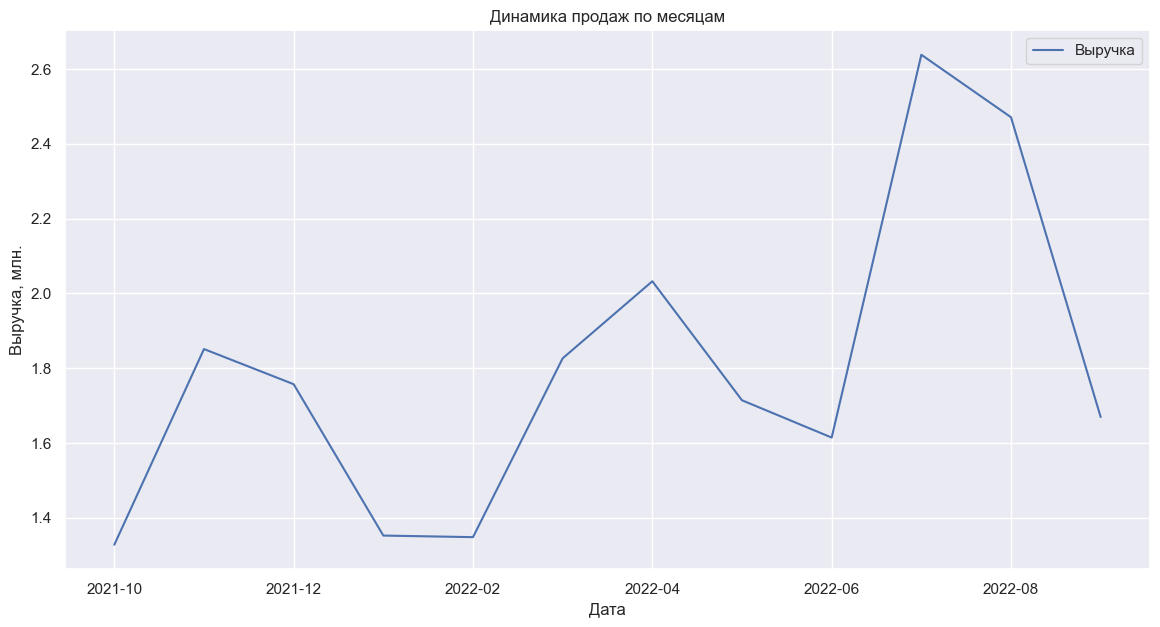

In [922]:
# сгруппируем данные по месяцам и возьмемем суммарную выручку
revenue = df.pivot_table(index=df['issue_date'].dt.strftime('%Y-%m'), aggfunc=lambda x: x.sum()/1000000, values='revenue')
# P.s сначала построил график по дням и понял, что он не информативный. Нашел на просторах интернета метод "strftime",
# чтобы выделить из даты месяц и год. После чего сгруппировал по месяцам.
# также решил убрать приписку 1е6, поделив все значения на 1 млн. 
# построим линейный график
revenue.plot(figsize=(14, 7),
            xlabel = 'Дата',
            ylabel = 'Выручка, млн.',
            title = 'Динамика продаж по месяцам')
plt.legend(['Выручка'])
plt.show()

Анализируя график выручки по месяцам, видно, что она сильно колеблется и имеет выраженную сезонность. Самый низкий уровень — в октябре 2021 (около 1.35 млн), затем рост до ноября (почти 1.9 млн), но потом падение в декабре и январе — минимальные значения (около 1.35–1.4 млн). С февраля начинается уверенный рост: к апрелю выручка достигает 2.05 млн, затем снижается до июня (1.6 млн). Но самый яркий скачок — в июле 2022 (почти 2.7 млн), после чего снова спад — август (2.5 млн) и сентябрь (1.7 млн). Это типично для авиабизнеса: летом — пик спроса из-за отпусков, зимой — спад.

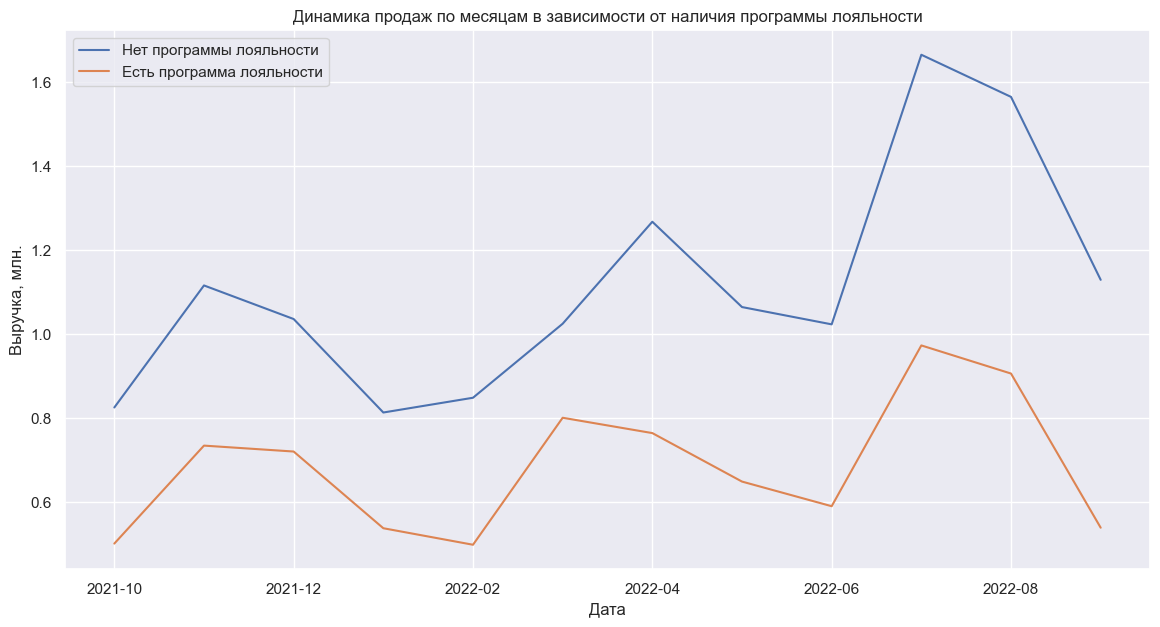

In [923]:
# взял структуру таблицы из предыдущего пункта и добавил в сводную таблицу столбец с детализацией
revenue_ffp = df.pivot_table(index=df['issue_date'].dt.strftime('%Y-%m'), aggfunc=lambda x: x.sum()/1000000, columns='ffp_flag', values='revenue')
# построим линейный график
revenue_ffp.plot(figsize=(14, 7),
            xlabel = 'Дата',
            ylabel = 'Выручка, млн.',
            title = 'Динамика продаж по месяцам в зависимости от наличия программы лояльности')
plt.legend(['Нет программы лояльности','Есть программа лояльности'])
plt.show()

Из графика видно, что клиенты с программой лояльности приносят значительно меньшую выручку по сравнению с теми, кто в неё не включён. Это логично: участники программы получают больше скидок и бонусов, что снижает их средний чек. Однако, несмотря на меньший вклад в выручку, такие клиенты могут быть ценнее с точки зрения долгосрочной лояльности и частоты покупок. Таким образом, хотя программы лояльности и используются меньшинством клиентов, их роль не стоит недооценивать — они способствуют удержанию аудитории и стабильному спросу, особенно вне пиковых сезонов. Также обе кривые демонстрируют выраженную сезонность.

ВВЛ - Внутренние Воздушные Линии
МВЛ - Международные Воздушные Линии


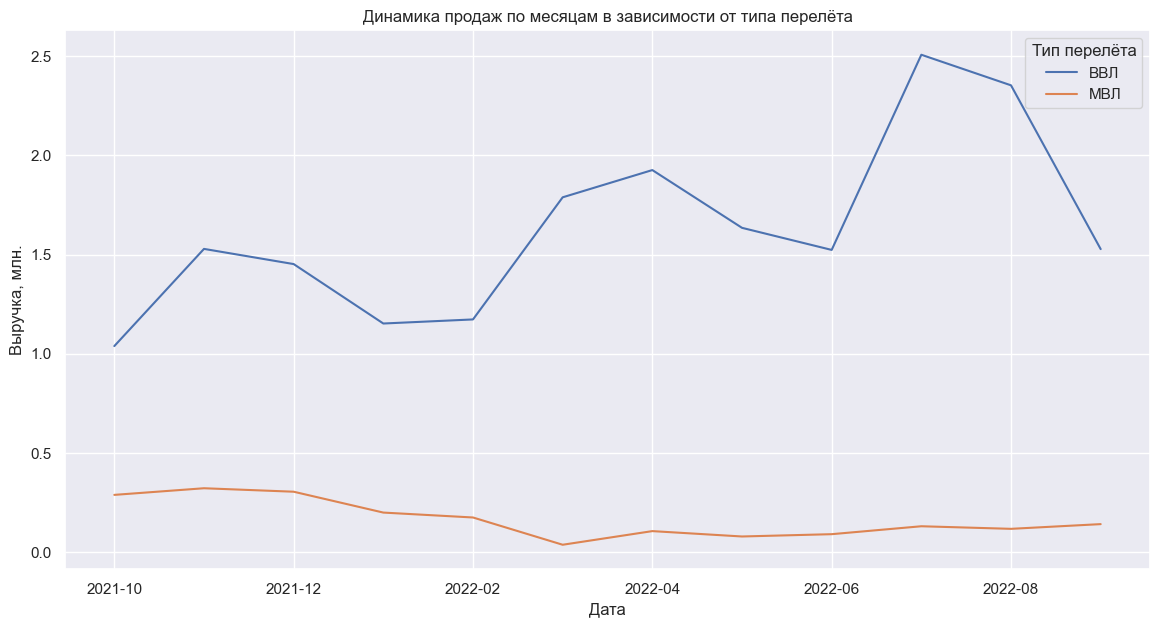

In [924]:
# взял структуру таблицы из предыдущего пункта и добавил в сводную таблицу столбец с детализацией
revenue_flight_type = df.pivot_table(index=df['issue_date'].dt.strftime('%Y-%m'), aggfunc=lambda x: x.sum()/1000000, columns='flight_type', values='revenue')
# построим линейный график
revenue_flight_type.plot(figsize=(14, 7),
            xlabel = 'Дата',
            ylabel = 'Выручка, млн.',
            title = 'Динамика продаж по месяцам в зависимости от типа перелёта')
plt.legend(title='Тип перелёта')
print('ВВЛ - Внутренние Воздушные Линии\nМВЛ - Международные Воздушные Линии')
plt.show()

Из графика видно, что основной вклад в выручку авиакомпании дают внутренние воздушные линии (ВВЛ) — их кривая значительно выше и колеблется в диапазоне от 1.0 до 2.5 млн. Международные линии (МВЛ) приносят гораздо меньше — максимум около 0.3–0.4 млн, а в отдельные месяцы (например, март 2022) почти не генерируют дохода. Это говорит о том, что бизнес компании в основном ориентирован на внутренний рынок, а международные рейсы играют вспомогательную или сезонную роль. Возможно, это связано с ограничениями, налоговыми условиями или меньшим спросом на МВЛ.

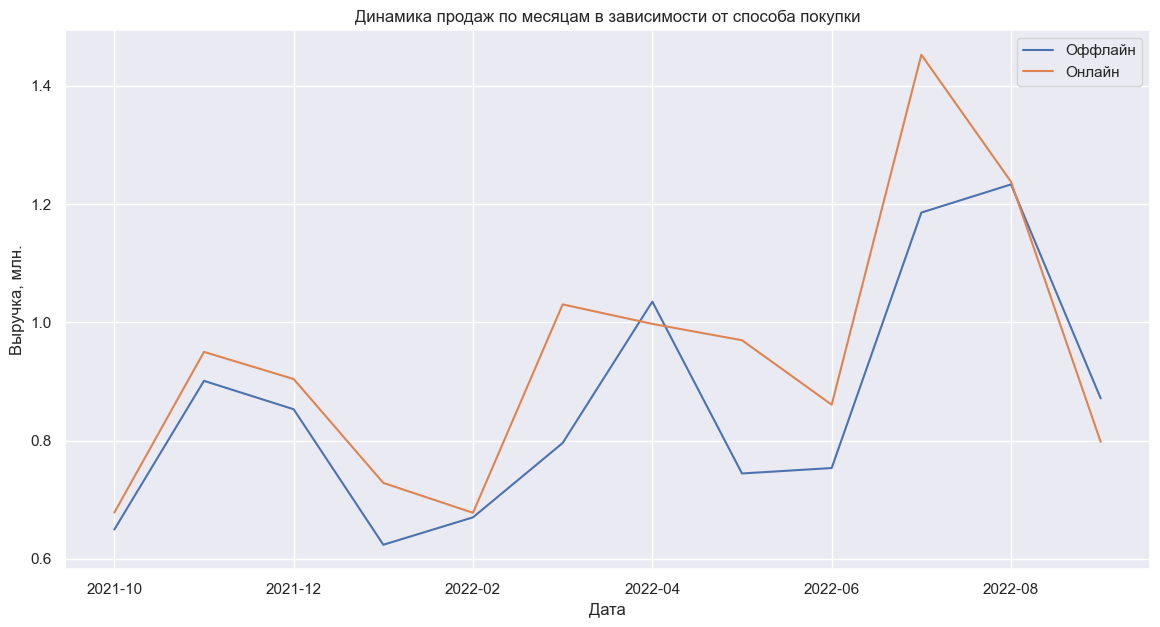

In [925]:
# взял структуру таблицы из предыдущего пункта и добавил в сводную таблицу столбец с детализацией
revenue_sale_type = df.pivot_table(index=df['issue_date'].dt.strftime('%Y-%m'), aggfunc=lambda x: x.sum()/1000000, columns='sale_type', values='revenue')
# построим линейный график
revenue_sale_type.plot(figsize=(14, 7),
            xlabel = 'Дата',
            ylabel = 'Выручка, млн.',
            title = 'Динамика продаж по месяцам в зависимости от способа покупки')
plt.legend(title='Способ покупки')
plt.legend(['Оффлайн','Онлайн'])
plt.show()

График показывает, что выручка от онлайн-покупок в целом превышает выручку от офлайн-продаж, особенно в пиковые месяцы — например, в июле 2022 года онлайн достигает почти 1.45 млн., тогда как офлайн — около 1.2 млн. Это говорит о том, что клиенты всё чаще предпочитают покупать билеты через интернет — возможно, из-за удобства, быстроты или большего выбора акций и скидок онлайн. При этом офлайн-продажи остаются стабильными, хотя и ниже: их уровень колеблется в районе 0.6–1.2 млн. Интересно, что в некоторых месяцах (например, апрель 2022) офлайн даже немного обгоняет онлайн, но это скорее исключение. Тренд на рост онлайн-продаж явный, и компании стоит усиливать цифровые каналы продаж.

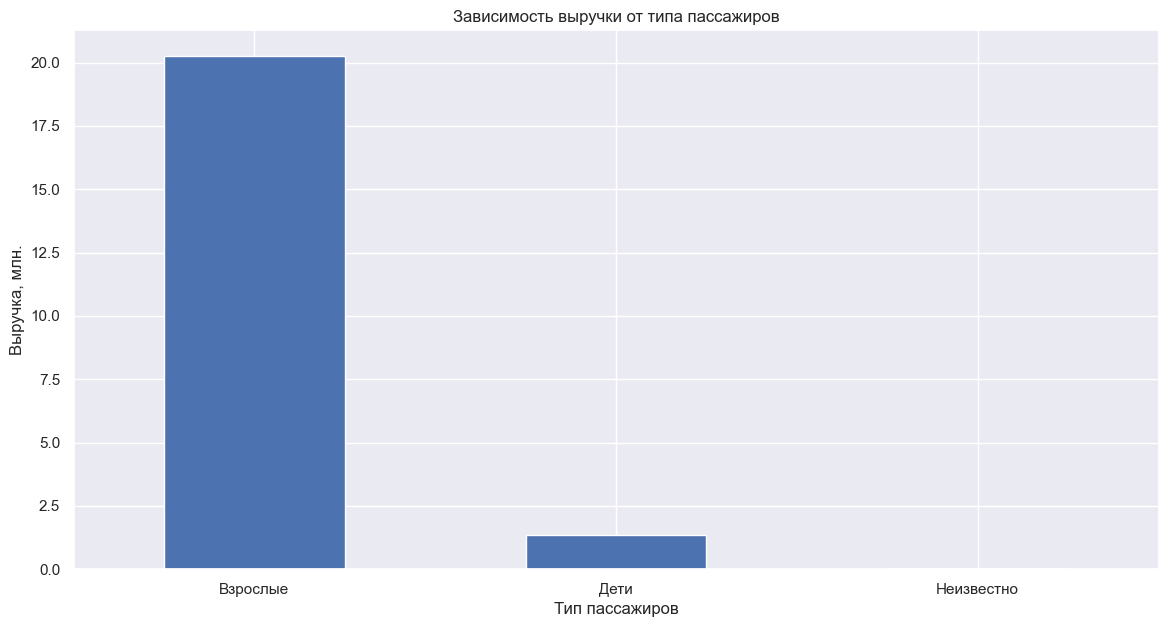

In [926]:
# построим сводную таблицу
revenue_pax_type = df.pivot_table(index='pax_type', aggfunc=lambda x: x.sum()/1000000, values='revenue')
# переименуем индексы
revenue_pax_type = revenue_pax_type.rename(index={
    "AD": "Взрослые",
    "CHD": "Дети",
    "INF": "Неизвестно"
})
revenue_pax_type.plot(kind='bar',
               figsize = (14,7),
               title='Зависимость выручки от типа пассажиров',
               rot=0,
               xlabel='Тип пассажиров',
               ylabel='Выручка, млн.',
               legend=False)
plt.show()

Из диаграммы видно, что основной вклад в выручку дают взрослые пассажиры — их доля составляет около двадцати миллионов, что подчёркивает их ключевую роль в бизнесе авиакомпании. Дети приносят значительно меньше — около полутора миллиона. Это объясняется тем, что дети не могут путешествовать без взрослых, а также тем, что дети в целом меньше совершают перелёты. К тому же на детские билеты обычно скидки. Категория «Неизвестно» практически не влияет на доход — её значение близко к нулю.

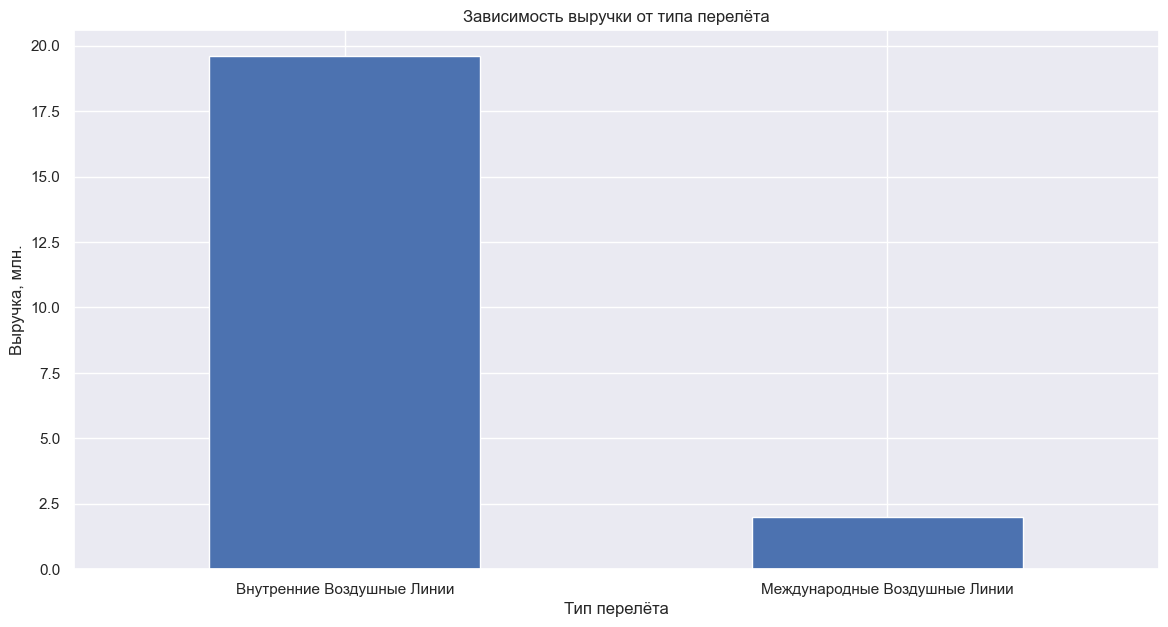

In [927]:
# построим сводную таблицу
revenue_flight_type_bar = df.pivot_table(index='flight_type', aggfunc=lambda x: x.sum()/1000000, values='revenue')
# переименуем индексы
revenue_flight_type_bar = revenue_flight_type_bar.rename(index = {"ВВЛ":"Внутренние Воздушные Линии","МВЛ":"Международные Воздушные Линии"})
revenue_flight_type_bar.plot(kind='bar',
               figsize = (14,7),
               title='Зависимость выручки от типа перелёта',
               rot=0,
               xlabel='Тип перелёта',
               ylabel='Выручка, млн.',
               legend=False)

plt.show()

Основной объём выручки компании формируется за счёт внутренних воздушных линий — их доля составляет почти двадцать миллионов, что в несколько раз превышает показатели международных рейсов. Это говорит о том, что бизнес авиакомпании в первую очередь ориентирован на внутренний рынок: клиенты чаще путешествуют по стране, возможно, из-за большей доступности цен, частоты рейсов или географической близости направлений. Международные линии приносят значительно меньше — около двух миллионов, что может быть связано с меньшим спросом, более высокой конкуренцией, сложностями в организации рейсов или ограничениями. Важно отметить, что даже небольшой вклад от международных перелётов всё же есть — значит, эта категория не должна игнорироваться. Компании стоит продолжать развивать внутренние маршруты как основной источник дохода, но также анализировать потенциал роста на международном рынке.

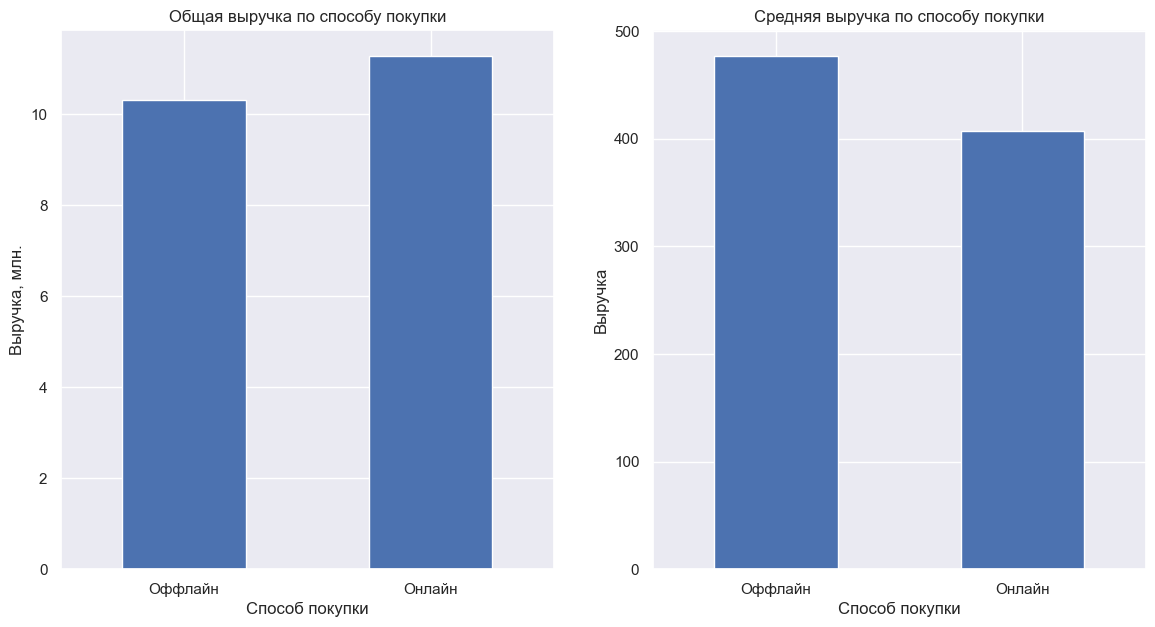

In [928]:
# на этом этапе я подумал, что было бы интересно рассмотреть зависимость выручки от способа покупки не только по общей вырчуке, а также
# основываясь на том, сколько людей покупает онлайн и оффлайн
# для этого в сводных таблицах буду исполшьзовать функцию mean, чтобы учесть популяцию каждой группы и lambda x: x.sum() из предыдущих пунктов

# сводные таблицы
revenue_sale_type_sum = df.pivot_table(index='sale_type', values='revenue', aggfunc=lambda x: x.sum() / 1000000)
revenue_sale_type_sum = revenue_sale_type_sum.rename(index={"OFFLINE": "Оффлайн", "ONLINE": "Онлайн"})

revenue_sale_type_mean = df.pivot_table(index='sale_type', values='revenue', aggfunc='mean')
revenue_sale_type_mean = revenue_sale_type_mean.rename(index={"OFFLINE": "Оффлайн", "ONLINE": "Онлайн"})

# два графика рядом
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))

# общая выручка
revenue_sale_type_sum.plot(kind='bar', ax=ax1, rot=0, legend=False)
ax1.set_title('Общая выручка по способу покупки')
ax1.set_xlabel('Способ покупки')
ax1.set_ylabel('Выручка, млн.')

# средняя выручка
revenue_sale_type_mean.plot(kind='bar', ax=ax2, rot=0, legend=False) 
ax2.set_title('Средняя выручка по способу покупки')
ax2.set_xlabel('Способ покупки')
ax2.set_ylabel('Выручка')

plt.show()

Проанализировав два графика, можно сделать вывод о том, что покупки билетов онлайн приносят компании больше выручки — 11.5 млн против 10 млн у оффлайн. Это объясняется тем, что онлайн-каналом пользуется значительно больше людей: он удобен, доступен в любое время суток, позволяет быстро сравнивать цены и получать скидки или бонусы. Особенно популярен он среди молодёжи, частых путешественников и тех, кто ориентирован на экономию.

В то же время средняя выручка на одну покупку выше именно в оффлайн. Это связано с тем, что те, кто обращается в кассы или агентства, чаще совершают более сложные бронирования — например, покупают билеты на несколько направлений, выбирают гибкие тарифы без ограничений или дополняют перелёт услугами, которые проще оформить с помощью консультанта. Кроме того, часть клиентов по-прежнему предпочитает личное взаимодействие — особенно это касается пожилых пассажиров или тех, кто не чувствует уверенности при самостоятельной покупке через интернет.

Таким образом, онлайн лидирует по объёмам за счёт массовости и удобства, а оффлайн генерирует более высокий чек за счёт сложных, премиальных или доверительных сделок. Это подчёркивает необходимость сохранять оба канала, адаптируя их под разные сегменты аудитории.

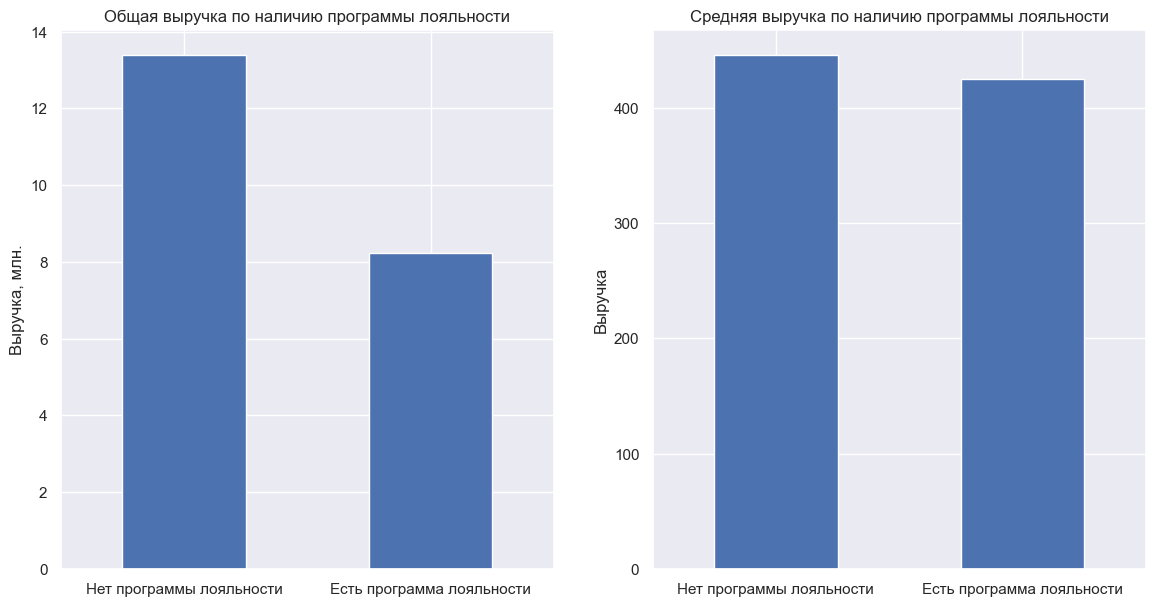

In [929]:
# сводные таблицы
revenue_ffp_sum = df.pivot_table(index='ffp_flag', values='revenue', aggfunc=lambda x: x.sum() / 1000000)
revenue_ffp_sum = revenue_ffp_sum.rename(index = {True:"Есть программа лояльности",False:"Нет программы лояльности"})

revenue_ffp_mean = df.pivot_table(index='ffp_flag', values='revenue', aggfunc='mean')
revenue_ffp_mean = revenue_ffp_mean.rename(index = {True:"Есть программа лояльности",False:"Нет программы лояльности"})

# два графика рядом
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))

# общая выручка
revenue_ffp_sum.plot(kind='bar', ax=ax1, rot=0, legend=False)
ax1.set_title('Общая выручка по наличию программы лояльности')
ax1.set_xlabel('') # я подумал, что подписи к столбцам сами по себе достаточно информативны и решил не называть ось абсцисс
ax1.set_ylabel('Выручка, млн.')

# средняя выручка
revenue_ffp_mean.plot(kind='bar', ax=ax2, rot=0, legend=False) 
ax2.set_title('Средняя выручка по наличию программы лояльности')
ax2.set_xlabel('')
ax2.set_ylabel('Выручка')

plt.show()

Сравнивая два графика, можно заметить, что общая выручка от клиентов без программы лояльности выше — около 13.5 млн против 8.2 млн у участников программы, это объясняется тем, что участников без программы лояльности значительно больше. При этом средняя выручка на одного клиента практически сопоставима: у участников программы — около 430, у остальных — 460. Это показывает, что, несмотря на предоставляемые скидки и бонусы, лояльные клиенты почти не уступают по уровню трат. Вероятно, они компенсируют скидки за счёт большей частоты полётов, выбора гибких тарифов или покупки дополнительных услуг. Такой баланс говорит о том, что программа лояльности выполняет свою роль — она не только удерживает клиентов, но и поддерживает их вовлечённость без серьёзного падения дохода на пользователя. Это даёт основание расширять программу: упрощать вступление, добавлять персонализированные привилегии или поощрять использование бонусов на допуслуги. В долгосрочной перспективе рост доли лояльных клиентов может привести к стабилизации выручки даже в периоды спада спроса.

### Исследование выручки

Исследуйте выручку, примите решение об исключении выбросов для дальнейшего исследования, руководствуясь минимизацией потерь в данных.

In [930]:
# посмотрим описание данных
df['revenue'].describe()

count    49365.000000
mean       437.631723
std        214.604891
min         10.000000
25%        290.000000
50%        400.000000
75%        550.000000
max       5200.000000
Name: revenue, dtype: float64

Из статистики видно, что средняя выручка на одну покупку составляет около 437 единиц, при этом медиана (50%) — 400. Так как среднее значение выше медианы, распределение смещено вправо — это означает, что большинство покупок сосредоточено в нижней и средней части диапазона, а небольшая часть клиентов совершает очень дорогие покупки, «тянув» среднее вверх. Минимальная сумма — всего 10, максимальная — 5200, что подтверждает наличие редких, но высокодоходных сделок. Стандартное отклонение — 214 — говорит о значительной вариативности цен. Квартили показывают, что 75% всех покупок не превышают 550, а 25% — меньше 290. Вывод: основная масса клиентов выбирает билеты в диапазоне 290–550, но есть небольшой сегмент, готовый платить значительно больше.

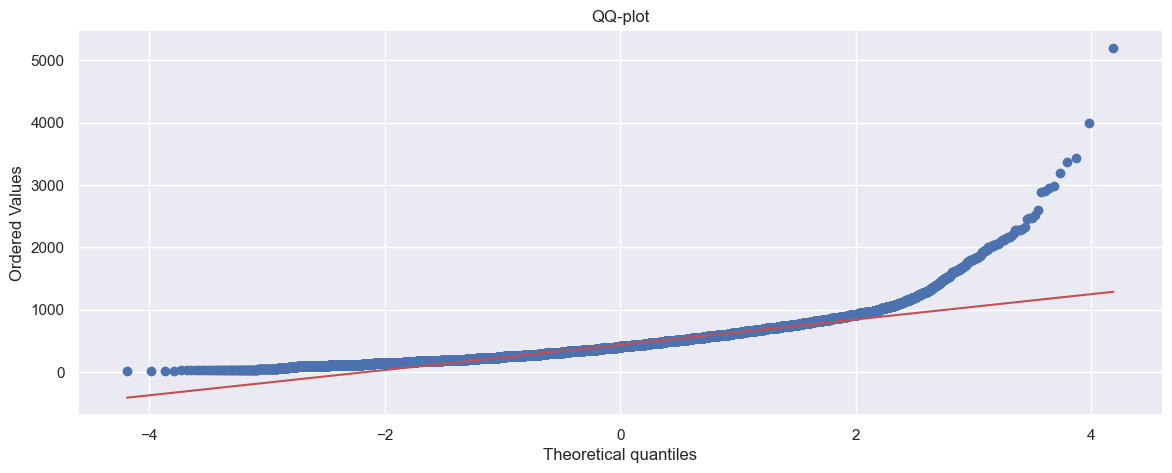

In [931]:
plt.figure(figsize=(14,5))
st.probplot(df['revenue'], dist='norm', plot=plt)
plt.title('QQ-plot')
plt.show()

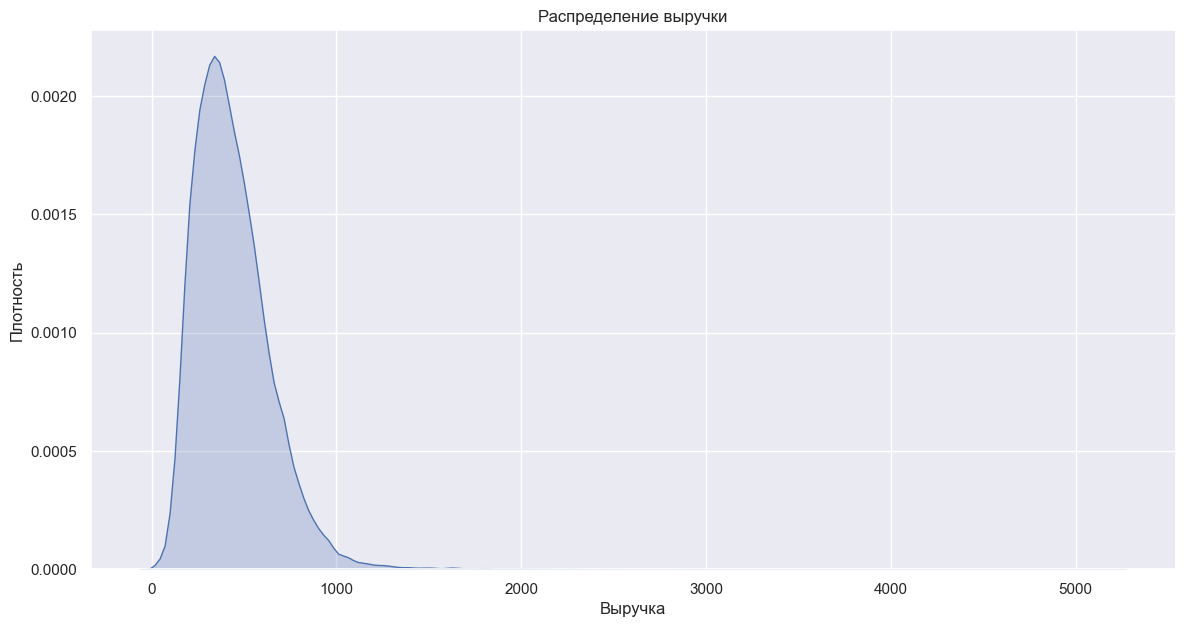

In [932]:
# посмотрим распределение данных
plt.figure(figsize=(14, 7))
sns.kdeplot(df['revenue'], fill=True)
plt.xlabel('Выручка')
plt.ylabel('Плотность')
plt.title('Распределение выручки')
plt.show()

По графикам видно, что распределение не является нормальным. Область графика смещена вправо, до значения 5200.

Правило трёх сигм для удаления выбросов в данном случае неприменимо, поскольку распределение выручки явно смещено вправо. Такое распределение не соответствует нормальному, а значит, использование 3σ может привести к некорректному исключению значимых данных. Вместо этого лучше применить метод межквартильного размаха (IQR), визуальный анализ через боксплот.

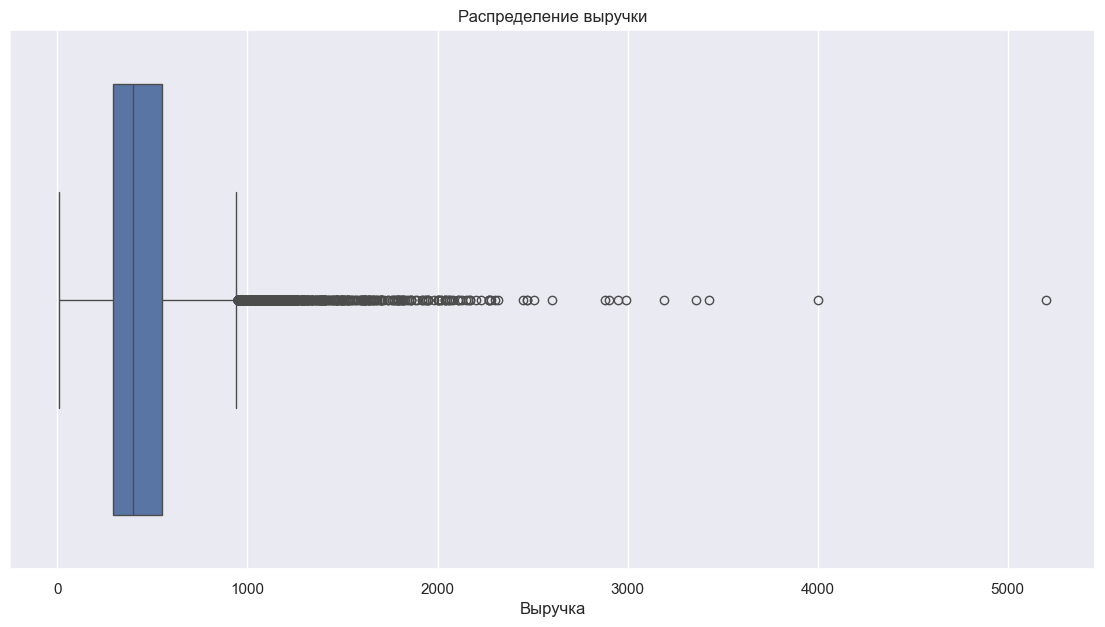

In [933]:
# построим boxplot, чтобы посмотреть на выбросы
plt.figure(figsize=(14, 7))
sns.boxplot(df['revenue'],
            orient='h')
plt.xlabel('Выручка')
plt.title('Распределение выручки')
plt.show()

На боксплоте отчётливо видно, что распределение выручки сильно смещено вправо — основная масса покупок сосредоточена в левой части графика, а длинный «хвост» тянется в сторону высоких значений. Медиана 400, что подтверждает, что половина всех сделок приходится на низкий и средний ценовой сегмент. При этом есть множество выбросов — отдельные точки справа, некоторые из которых достигают 4000–5000, что говорит о наличии клиентов, совершающих очень дорогие покупки. Это может быть связано с выбором бизнес-класса, групповыми билетами, сложными маршрутами или дополнительными услугами.

In [934]:
# найдем IQR и посмотрим, сколько выбросов получится
iqr = df['revenue'].quantile(0.75)-df['revenue'].quantile(0.25)
upper = df['revenue'].quantile(0.75)+1.5*iqr
count = df.query('revenue > @upper')['revenue'].count()
print(f'Кол-во выбросов: {count}')

Кол-во выбросов: 987


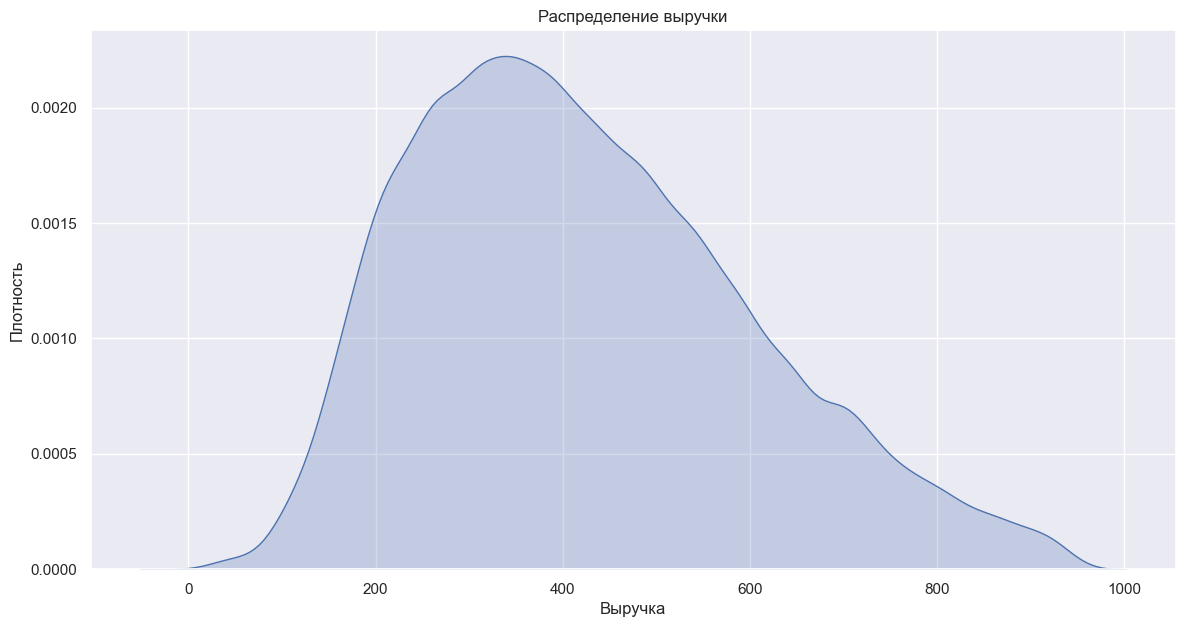

In [935]:
# удалим выбросы
df.drop(df.query('revenue > @upper').index, axis=0, inplace=True)
# посмотрим, как теперь выглядит распредление
plt.figure(figsize=(14, 7))
sns.kdeplot(df['revenue'], fill=True)
plt.xlabel('Выручка')
plt.ylabel('Плотность')
plt.title('Распределение выручки')
plt.show()

Несмотря на удаление выбросов, распределение выручки осталось скошенным вправо — пик плотности находится в левой части (около 350–400), а длинный хвост тянется к более высоким значениям. Это означает, что даже после фильтрации экстремальных значений основная масса покупок всё ещё сосредоточена в низком и среднем ценовом диапазоне, а высокие чеки встречаются реже, но остаются частью естественной структуры данных.

In [936]:
df['revenue'].describe()

count    48378.000000
mean       421.942205
std        178.542393
min         10.000000
25%        280.000000
50%        400.000000
75%        540.000000
max        940.000000
Name: revenue, dtype: float64

После удаления выбросов среднее значение выручки снизилось с 437 до 421, а максимальное — с 5200 до 940, что говорит о том, что были отсечены самые дорогие сделки. При этом медиана не изменилась, а 75-й перцентиль упал с 550 до 540. Это подтверждает, что распределение осталось скошенным: основная масса данных сконцентрирована в левой части, а «хвост» стал короче, но не исчез. Стандартное отклонение также уменьшилось — с 214 до 178, что указывает на снижение разброса, но не на нормализацию формы. Удаление выбросов помогло сделать данные «чище», но не привело к симметрии.

### Исследование сезонности продаж

Исследуйте сезонность продаж. Дополнительно проверьте гипотезу о том, что выручка от продаж осенью и зимой отличается. Исследуйте выручку и число продаж по месяцам, проверьте корреляцию.

In [937]:
# создадим новый столбец с названием сезона
# для этого нам понадобится словарь
season_sales = {
    1: 'Зима', 2: 'Зима', 3: 'Весна',
    4: 'Весна', 5: 'Весна', 6: 'Лето',
    7: 'Лето', 8: 'Лето', 9: 'Осень',
    10: 'Осень', 11: 'Осень', 12: 'Зима'
}
df['season_sales'] = df['issue_date'].dt.month.map(season_sales)
df.head(5)

,issue_date,flight_date,pax_type,revenue,orig_city_code,dest_city_code,flight_type,ffp_flag,sale_type,season_sales
0,2021-12-07,2022-01-11,AD,200,MOW,KGD,ВВЛ,False,ONLINE,Зима
1,2021-12-31,2022-01-03,AD,610,UUS,OVB,ВВЛ,False,OFFLINE,Зима
2,2021-11-28,2022-01-04,AD,390,KGD,MOW,ВВЛ,True,ONLINE,Осень
3,2021-12-08,2022-01-05,AD,190,VOZ,MOW,ВВЛ,False,ONLINE,Зима
4,2021-12-08,2022-01-12,AD,190,MOW,KRR,ВВЛ,True,OFFLINE,Зима


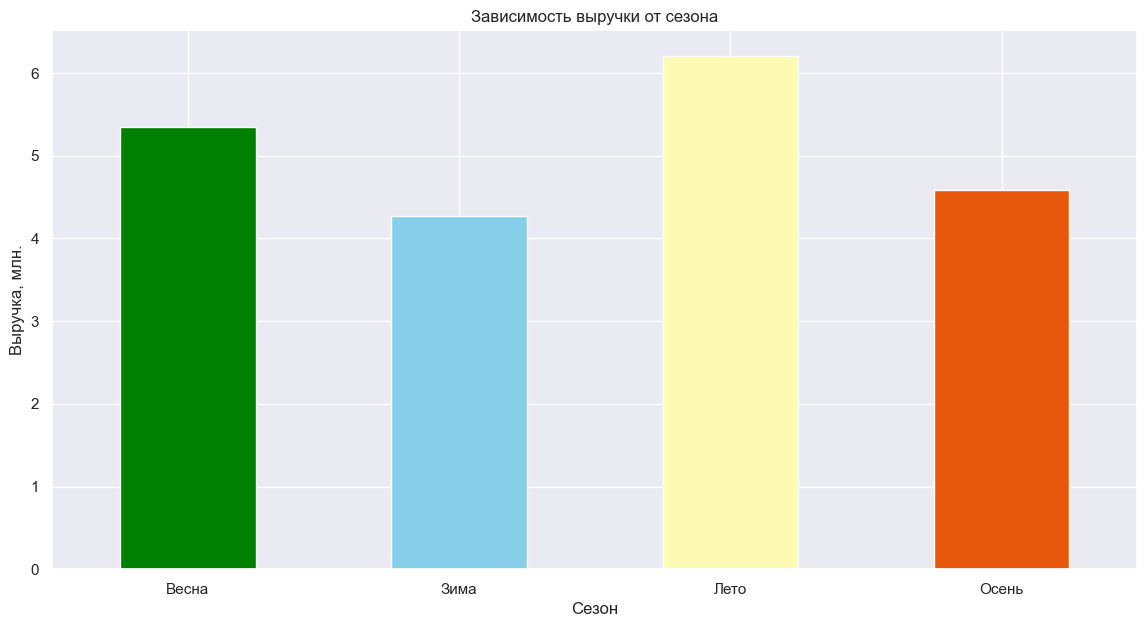

In [938]:
# группируем по сезону и суммируем выручку, чтобы посмотреть зависимость выручки от сезона
season_sales_revenue = df.groupby('season_sales')['revenue'].sum() / 1_000_000
# сделал с помощью groupby, потому что не получилось перекрасить в разные цвета диаграмму на основе pivot_table
# строим столбчатую диаграмму
season_sales_revenue.plot(
    kind='bar',
    figsize=(14, 7),
    title='Зависимость выручки от сезона',
    rot=0,
    xlabel='Сезон',
    ylabel='Выручка, млн.',
    legend=False,
    color = ['green', 'skyblue', '#fdfab5', '#e7580d']
)
plt.show()

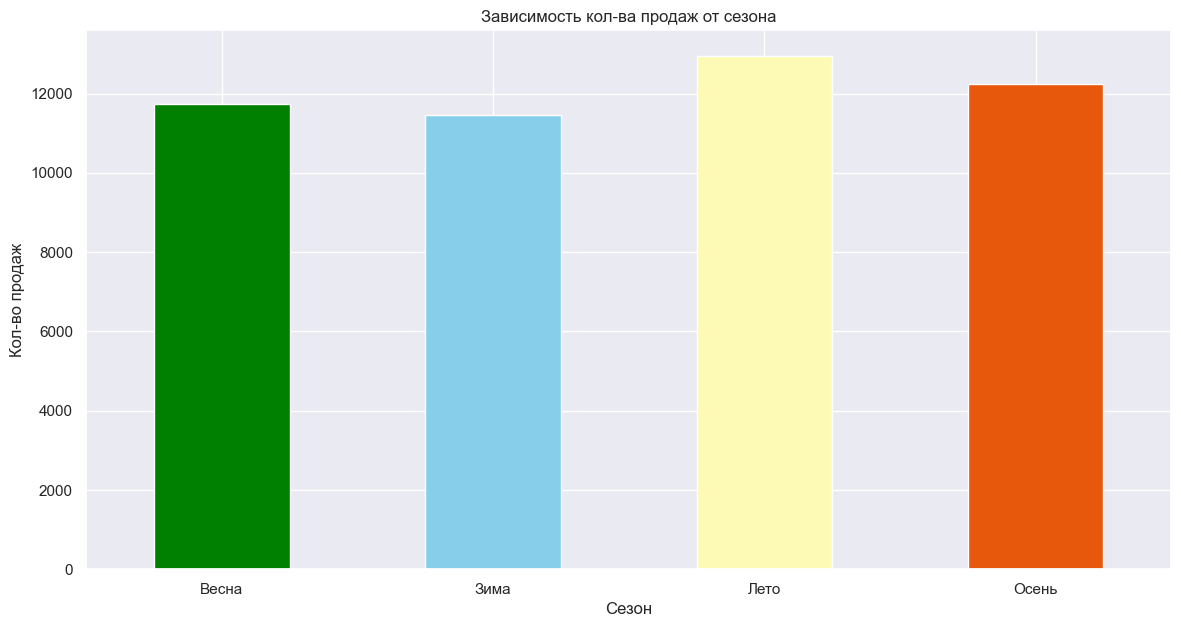

In [939]:
# группируем по сезону и считаем кол-во, чтобы посмотреть зависимость кол-ва продаж от сезона
season_sales_revenue = df.groupby('season_sales')['revenue'].count()
# строим столбчатую диаграмму
season_sales_revenue.plot(
    kind='bar',
    figsize=(14, 7),
    title='Зависимость кол-ва продаж от сезона',
    rot=0,
    xlabel='Сезон',
    ylabel='Кол-во продаж',
    legend=False,
    color = ['green', 'skyblue', '#fdfab5', '#e7580d']
)
plt.show()

На графиках отчётливо видно, что выручка сильно зависит от сезона: летом компания зарабатывает больше всего — около 6.2 млн, что делает этот период пиковым по спросу. Лето — время отпусков, семейных путешествий и активного туризма. На втором месте — весна, с выручкой около 5.3 млн, что также объяснимо: майские праздники, начало бронирования летних поездок и улучшение погоды стимулируют спрос. Осень приносит около 4.6 млн — это уже спад после летнего пика, но всё ещё значительный уровень, возможно, за счёт «бархатного сезона» или деловых поездок. Зима — наименее доходный сезон: всего 4.2 млн, что связано с окончанием новогодних каникул и снижением туристической активности. Вместе с тем, анализ количества продаж показывает, что лето — не только лидер по выручке, но и по объёму продаж (более 12 500), что подтверждает высокую вовлечённость клиентов в этот период. Весна и осень почти равны по числу покупок — около 11 700–12 100, что говорит о сохранении спроса даже вне пикового сезона. Зима остаётся самым слабым периодом по обоим показателям — и по выручке, и по количеству продаж (около 11 400). Это означает, что сезонность влияет не только на выручку, но и на общее количество продаж.



In [940]:
# в моменте исследования подумал, что часть людей берет билеты заранее, чтобы не переплачивать в пиковые сезоны.
# Решил проверить, насколько отличаются кол-во продаж и кол-во вылетов в разные сезоны
# создадим новый столбец с названием сезона
season_flights = {
    1: 'Зима', 2: 'Зима', 3: 'Весна',
    4: 'Весна', 5: 'Весна', 6: 'Лето',
    7: 'Лето', 8: 'Лето', 9: 'Осень',
    10: 'Осень', 11: 'Осень', 12: 'Зима'
}
df['season_flights'] = df['flight_date'].dt.month.map(season_flights)
df.head(5)

,issue_date,flight_date,pax_type,revenue,orig_city_code,dest_city_code,flight_type,ffp_flag,sale_type,season_sales,season_flights
0,2021-12-07,2022-01-11,AD,200,MOW,KGD,ВВЛ,False,ONLINE,Зима,Зима
1,2021-12-31,2022-01-03,AD,610,UUS,OVB,ВВЛ,False,OFFLINE,Зима,Зима
2,2021-11-28,2022-01-04,AD,390,KGD,MOW,ВВЛ,True,ONLINE,Осень,Зима
3,2021-12-08,2022-01-05,AD,190,VOZ,MOW,ВВЛ,False,ONLINE,Зима,Зима
4,2021-12-08,2022-01-12,AD,190,MOW,KRR,ВВЛ,True,OFFLINE,Зима,Зима


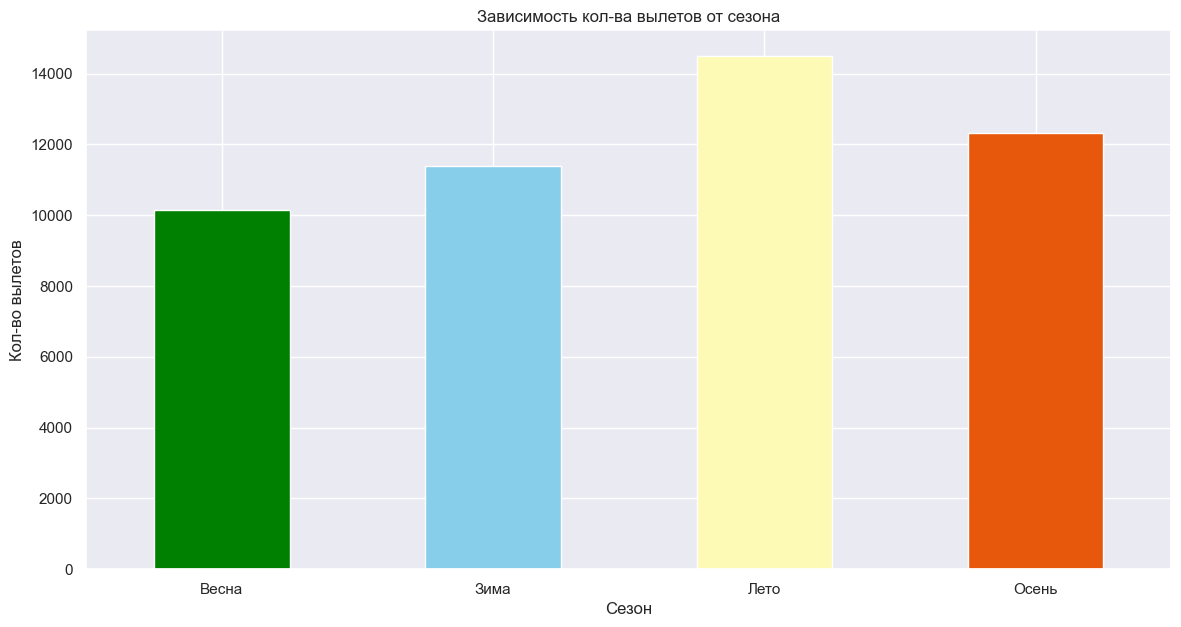

In [941]:
# группируем по сезону и считаем кол-во вылетов, чтобы посмотреть зависимость кол-ва вылетов от сезона
season_sales_revenue = df.groupby('season_flights')['revenue'].count()
# строим столбчатую диаграмму
season_sales_revenue.plot(
    kind='bar',
    figsize=(14, 7),
    title='Зависимость кол-ва вылетов от сезона',
    rot=0,
    xlabel='Сезон',
    ylabel='Кол-во вылетов',
    legend=False,
    color = ['green', 'skyblue', '#fdfab5', '#e7580d']
)
plt.show()

Диаграмма подтверждает разницу в количестве продаж и вылетов по сезонам. При этом значения зимой и осенью остались примерно такие же, как и в предыщем пункте. Разница проявляется весной и летом. На графике видно, как часть продаж весной перешла в кол-во вылетов летом. Такое наблюдение показывает, что люди заранее весной покупают билеты на пиковый сезон. Разница составляет примерно 1500.

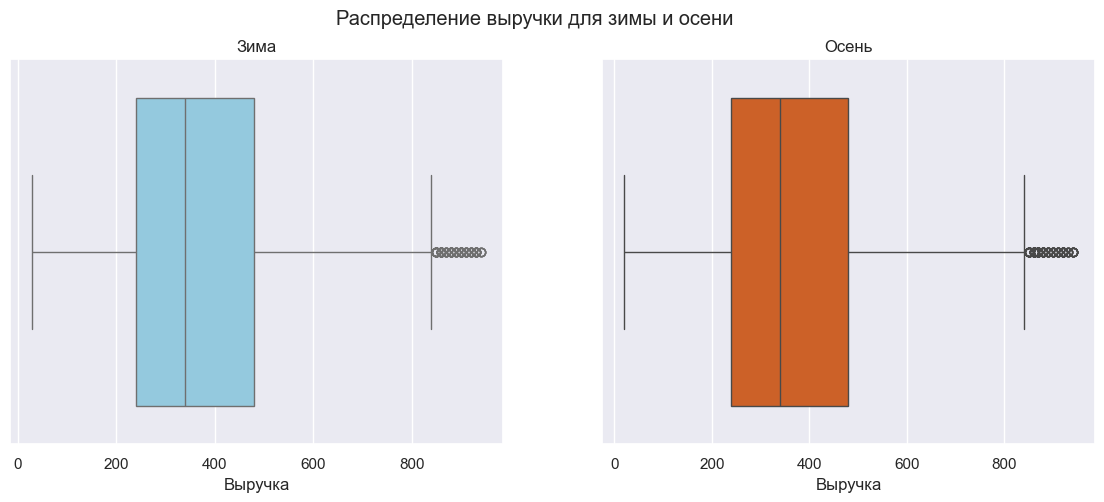

In [942]:
# проверим гипотезу о том, что выручка от продаж осенью и зимой отличается

# для начала проверим данные на нормальность распределения

# фильтруем данные
winter = df.query('season_sales == "Зима"')['revenue']
autumn = df.query('season_sales == "Осень"')['revenue']

# создаём фигуру с двумя подграфиками
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# боксплот для зимы
sns.boxplot(winter, ax=ax1, orient='h', color='skyblue')
ax1.set_title('Зима')
ax1.set_xlabel('Выручка')

# боксплот для осени
sns.boxplot(autumn, ax=ax2, orient='h', color='#e7580d')
ax2.set_title('Осень')
ax2.set_xlabel('Выручка')

fig.suptitle('Распределение выручки для зимы и осени')
plt.show()

Из боксплотов видно, что распределения выручки в обеих группах (зима и осень) заметно отличаются от нормального — присутствуют выбросы, асимметрия и длинные хвосты. В таких условиях применение t-теста было бы некорректным, так как он чувствителен к нарушению предположений о нормальности. Поэтому для сравнения двух независимых выборок логичнее использовать непараметрический тест Манна–Уитни, который не требует нормальности и устойчив к выбросам.

In [943]:
# Н0: выручка от продаж осенью и зимой не отличается
# Н1: выручка от продаж осенью и зимой отличается
stat, p_value = st.mannwhitneyu(winter, autumn)
alpha = 0.05
if p_value < alpha:
    print(f"p-value = {p_value:.3f} < {alpha} → отклоняем H₀")
    print("Выручка осенью и зимой статистически значимо отличаются.")
else:
    print(f"p-value = {p_value:.3f} ≥ {alpha} → нет оснований отклонять H₀")
    print("Нет статистически значимых различий в выручке между осенью и зимой.")

p-value = 0.458 ≥ 0.05 → нет оснований отклонять H₀
Нет статистически значимых различий в выручке между осенью и зимой.


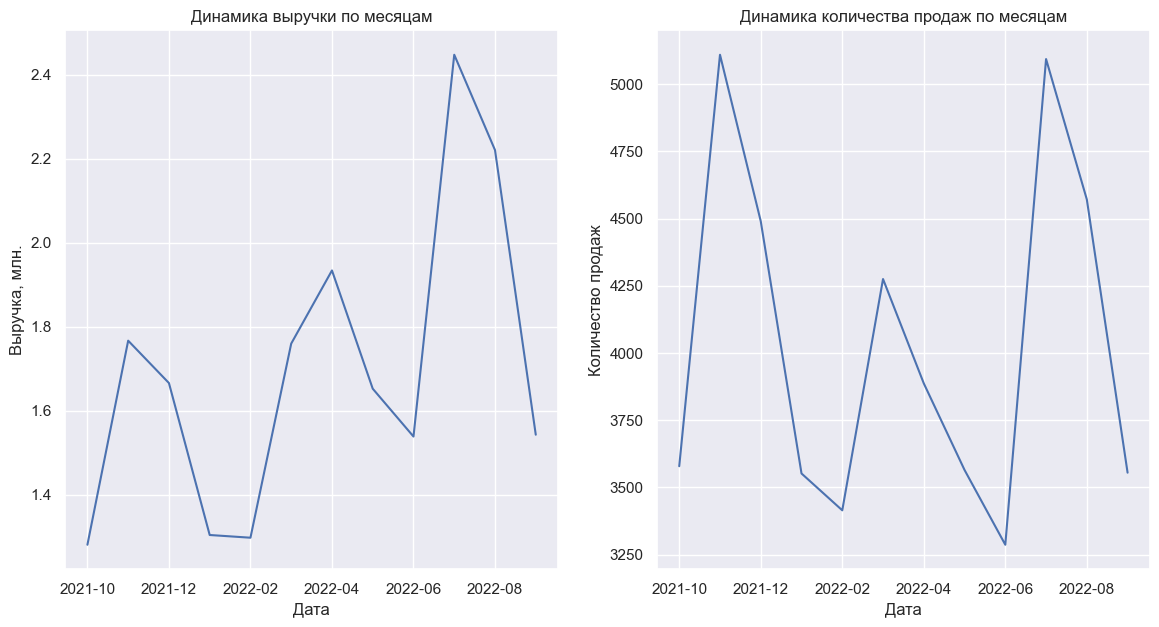

In [944]:
# посмотрим динамику по месяцам
# пивот для выручки
month_revenue = df.pivot_table(
    index=df['issue_date'].dt.strftime('%Y-%m'),
    values='revenue',
    aggfunc=lambda x: x.sum() / 1_000_000
)
# пивот для кол-ва продаж
month_count = df.pivot_table(
    index=df['issue_date'].dt.strftime('%Y-%m'),
    values='revenue',
    aggfunc='count'
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))

# график выручки
month_revenue.plot(
    ax=ax1,
    kind='line',
    xlabel='Дата',
    ylabel='Выручка, млн.',
    title='Динамика выручки по месяцам',
    legend=False
)
# график количества продаж
month_count.plot(
    ax=ax2,
    xlabel='Дата',
    ylabel='Количество продаж',
    title='Динамика количества продаж по месяцам',
    legend=False
)

plt.show()

На графиках отчётливо прослеживается выраженная сезонная динамика: выручка, и количество продаж демонстрируют схожие пики. Ожидаемый максимум приходится на июль 2022 года, что связано с пиком летнего туристического сезона — отпусками, семейными поездками и высоким спросом на перелёты.
Однако особенно примечательным выглядит резкий скачок числа продаж в ноябре 2021 года, при этом выручка относительно небольшая. Это выбивается из типичной картины «зима — низкий сезон» и, скорее всего, связано с ранним бронированием новогодних и зимних каникул — клиенты покупают билеты заранее, чтобы сэкономить или обеспечить себе места. Возможно, также сыграли роль специальные акции или распродажи в преддверии праздников. Минимальные значения приходятся на январь–февраль, когда спрос падает после праздников.

In [945]:
# проверим корреляцию
# для этого создадим таблицу с выручкой и числом продаж по месяцам
months = {
    1: 'Январь',
    2: 'Февраль',
    3: 'Март',
    4: 'Апрель',
    5: 'Май',
    6: 'Июнь',
    7: 'Июль',
    8: 'Август',
    9: 'Сентябрь',
    10: 'Октябрь',
    11: 'Ноябрь',
    12: 'Декабрь'
}
month_revenue_count = df.pivot_table(index=df['issue_date'].dt.month.map(months), aggfunc=['sum', 'count'], values='revenue').reset_index()
month_revenue_count.columns = ['month', 'revenue', 'count']
month_revenue_count

,month,revenue,count
0,Август,2220920,4571
1,Апрель,1934200,3887
2,Декабрь,1666010,4490
3,Июль,2447960,5093
4,Июнь,1538600,3287
5,Май,1652560,3565
6,Март,1759960,4275
7,Ноябрь,1766940,5109
8,Октябрь,1280870,3579
9,Сентябрь,1542980,3555


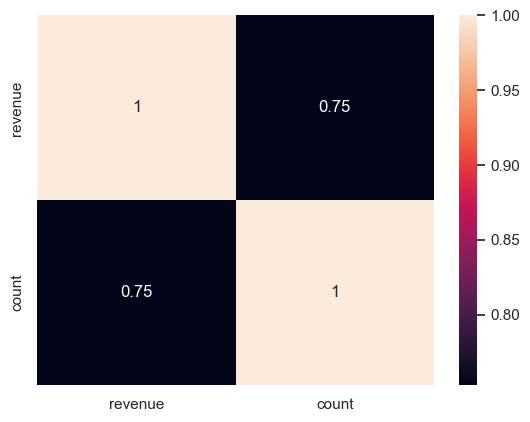

In [946]:
corr = month_revenue_count[['revenue', 'count']].corr()
sns.heatmap(corr, annot=True)
plt.show()

На тепловой карте видно, что между выручкой и количеством продаж существует сильная положительная корреляция — коэффициент равен 0.75. Это означает, что рост числа продаж напрямую связан с увеличением общей выручки: чем больше билетов продано, тем выше доход компании.

### Анализ времени покупки билета

 Клиенты покупают билеты в разное время. Кто-то покупает билеты заранее, другие - в последний момент. Проверьте гипотезу о том, что выручка от продажи билетов для этих двух групп клиентов отличается. Предварительно разбейте клиентов минимум на три группы.

In [947]:
# добавим столбец с разницей во времени
df['date_diff'] = (df['flight_date']-df['issue_date']).dt.days
df.head(1)

,issue_date,flight_date,pax_type,revenue,orig_city_code,dest_city_code,flight_type,ffp_flag,sale_type,season_sales,season_flights,date_diff
0,2021-12-07,2022-01-11,AD,200,MOW,KGD,ВВЛ,False,ONLINE,Зима,Зима,35


In [948]:
# разделим время покупки на раннее, среднее, позднее с помощью 25 и 75 квантиля
df['date_diff_name'] = pd.cut(df['date_diff'], right = False, bins = [0, df['date_diff'].quantile(0.25), df['date_diff'].quantile(0.75), df['date_diff'].max()+1], labels=['поздно', 'средне', 'рано'])
df.head(1)

,issue_date,flight_date,pax_type,revenue,orig_city_code,dest_city_code,flight_type,ffp_flag,sale_type,season_sales,season_flights,date_diff,date_diff_name
0,2021-12-07,2022-01-11,AD,200,MOW,KGD,ВВЛ,False,ONLINE,Зима,Зима,35,рано


In [949]:
# создадим новые датасеты
early = df.query('date_diff_name == "рано"')
normal = df.query('date_diff_name == "средне"')
last = df.query('date_diff_name == "поздно"')

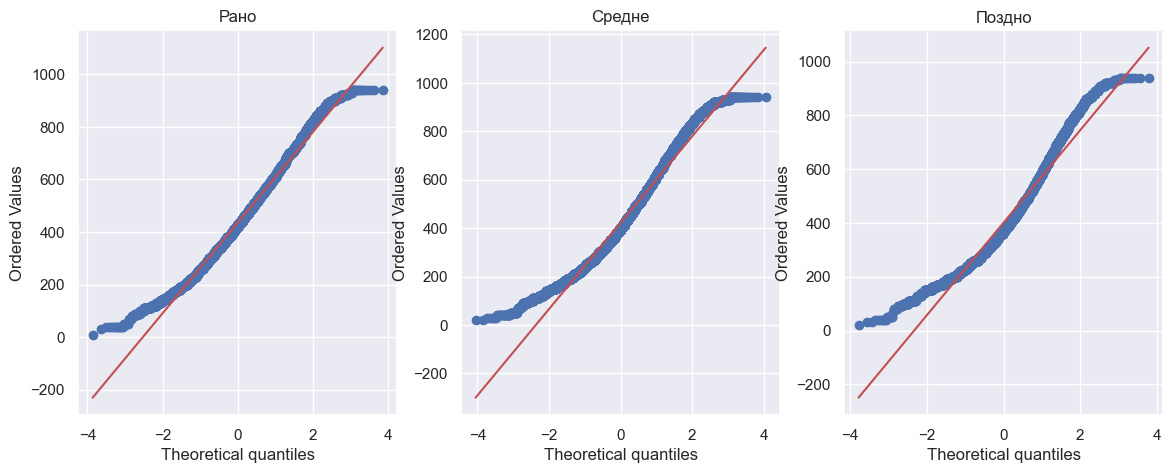

In [950]:
# посмотрим распределения
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 5))

# QQ-плот для рано
st.probplot(early['revenue'], dist='norm', plot=ax1)
ax1.set_title('Рано')

# QQ-плот для средне
st.probplot(normal['revenue'], dist='norm', plot=ax2)
ax2.set_title('Средне')

# QQ-плот для поздно
st.probplot(last['revenue'], dist='norm', plot=ax3)
ax3.set_title('Поздно')

plt.show()

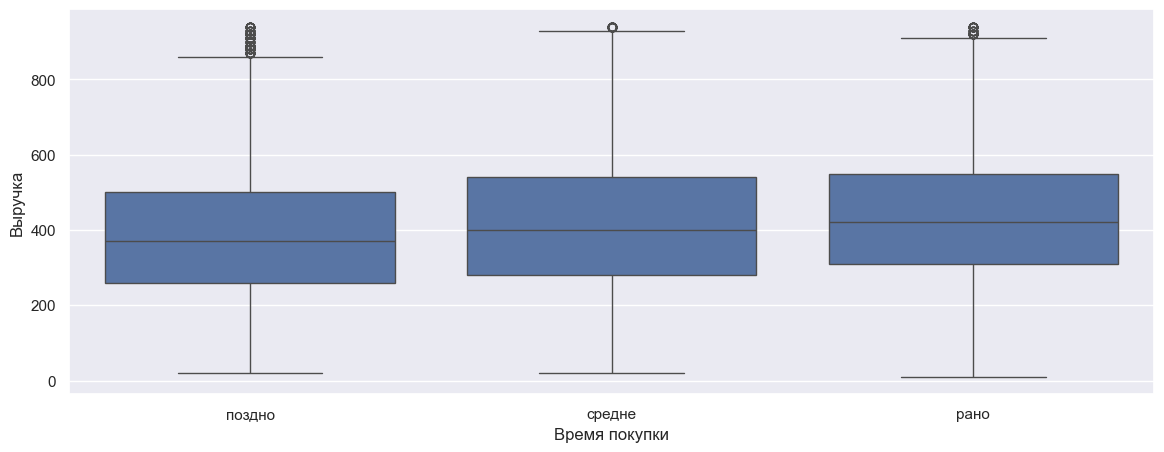

In [951]:
#посмотрим, как распределена выручка по этим группам через график боксплот
plt.figure(figsize=(14, 5))
sns.boxplot(df, x='date_diff_name', y='revenue').set(xlabel='Время покупки',
                                                    ylabel='Выручка')
plt.show()

На графиках видно, что распределение выручки в трёх группах — «рано», «средне» и «поздно» — имеет схожую форму, но разный масштаб: чем позже покупка, тем выше медианная и максимальная выручка. Это говорит о том, что клиенты, бронирующие билеты в последний момент, готовы платить больше — возможно, из-за срочности, отсутствия альтернатив или выбора более дорогих тарифов. На QQ-графиках видно, что распределения ненормальные — есть небольшие отклонения, особенно в хвостах, что подтверждает наличие выбросов и перекосов. Боксплоты наглядно показывают, что группа «поздно» имеет самый высокий средний чек, а «рано» — самый низкий, при этом у всех трёх групп есть выбросы. Для проверки гипотезы буду исследовать группы "поздно" и "рано".

In [952]:
# т.к. распределение ненормальное, буду использовать тест Манна-Уитни
# Н0: выручка от продажи билетов заранее и в последний момент не отличается
# Н1: выручка от продажи билетов заранее и в последний момент отличается
stat, p_value = st.mannwhitneyu(early['revenue'], last['revenue'])
alpha = 0.05
if p_value < alpha:
    print(f"p-value = {p_value} < {alpha} → отклоняем H₀")
    print("Выручка от продажи билетов заранее и в последний момент статистически значимо отличаются.")
else:
    print(f"p-value = {p_value} ≥ {alpha} → нет оснований отклонять H₀")
    print("Нет статистически значимых различий в выручке от продажи билетов заранее и в последний момент")

p-value = 2.005812877661498e-62 < 0.05 → отклоняем H₀
Выручка от продажи билетов заранее и в последний момент статистически значимо отличаются.


In [953]:
# Посмотрим средние значения выручки по этим категориям
print(f"Средняя выручка при ранней покупке билета: {early['revenue'].mean()}\nСредняя выручка при поздней покупке билета: {last['revenue'].mean()}")

Средняя выручка при ранней покупке билета: 435.64804971788374
Средняя выручка при поздней покупке билета: 400.93044162265426


Проведённый анализ показывает, что билеты, приобретённые в последний момент — непосредственно перед вылетом, — в среднем стоят дешевле чем купленные заранее. Странность заключается в том, что клиенты, купившие билеты заранее, в среднем платят больше, чем те, кто бронирует в последний момент — это противоречит общепринятой рыночной логике. Обычно авиакомпании используют динамическое ценообразование: самые дешёвые тарифы доступны при раннем бронировании, а цены растут по мере приближения даты вылета из-за роста спроса и сокращения числа свободных мест.

### Анализ направлений перелета

Определите топ-10 популярных направлений перелета (город-город) отдельно для ВМЛ и МВЛ. Изучите выручку для этих направлений. Для этого добавьте в датасет сведения о городах, используя данные из датасета: https://raw.githubusercontent.com/jpatokal/openflights/master/data/airports.dat

In [954]:
df.head(1)

,issue_date,flight_date,pax_type,revenue,orig_city_code,dest_city_code,flight_type,ffp_flag,sale_type,season_sales,season_flights,date_diff,date_diff_name
0,2021-12-07,2022-01-11,AD,200,MOW,KGD,ВВЛ,False,ONLINE,Зима,Зима,35,рано


In [955]:
air = pd.read_csv('https://raw.githubusercontent.com/jpatokal/openflights/master/data/airports.dat', header=None)

#изменим столбцы
air = air.drop(0, axis=1)
air.columns = ['Airport_Name', 'Location', 'Country', 'IATA_Code', 'ICAO_Code', 'Latitude', 'Longitude', 'Altitude', 'Timezone', 'DST', 'Timezone_Region', 'Type', 'Source']
air.columns = air.columns.str.lower()

#посмотрим данные
air.head(1)

,airport_name,location,country,iata_code,icao_code,latitude,longitude,altitude,timezone,dst,timezone_region,type,source
0,Goroka Airport,Goroka,Papua New Guinea,GKA,AYGA,-6.08169,145.391998,5282,10,U,Pacific/Port_Moresby,airport,OurAirports


In [956]:
# применим метод merge чтобы объединить таблицы по коду города
df = pd.merge(
    df,
    air[['iata_code','location']].rename(columns={'location': 'orig_city'}),  
    left_on='orig_city_code',           
    right_on='iata_code',            
    how='left').drop('iata_code', axis=1)
df = pd.merge(
    df,
    air[['iata_code','location']].rename(columns={'location': 'dest_city'}),  
    left_on='dest_city_code',           
    right_on='iata_code',            
    how='left').drop('iata_code', axis=1)

In [957]:
df.head()

,issue_date,flight_date,pax_type,revenue,orig_city_code,dest_city_code,flight_type,ffp_flag,sale_type,season_sales,season_flights,date_diff,date_diff_name,orig_city,dest_city
0,2021-12-07,2022-01-11,AD,200,MOW,KGD,ВВЛ,False,ONLINE,Зима,Зима,35,рано,NaN,Kaliningrad
1,2021-12-31,2022-01-03,AD,610,UUS,OVB,ВВЛ,False,OFFLINE,Зима,Зима,3,средне,Yuzhno-sakhalinsk,Novosibirsk
2,2021-11-28,2022-01-04,AD,390,KGD,MOW,ВВЛ,True,ONLINE,Осень,Зима,37,рано,Kaliningrad,NaN
3,2021-12-08,2022-01-05,AD,190,VOZ,MOW,ВВЛ,False,ONLINE,Зима,Зима,28,рано,Voronezh,NaN
4,2021-12-08,2022-01-12,AD,190,MOW,KRR,ВВЛ,True,OFFLINE,Зима,Зима,35,рано,NaN,Krasnodar


In [958]:
# посмотрим, каких городов не хватает
df.query('orig_city.isna()')['orig_city_code'].unique()

array(['MOW', 'PAR', 'BAK', 'ROM', 'SEL', 'BER', 'GRV', 'NQZ', 'OHH',
       'TOX', 'MIL', 'TYO', 'LON'], dtype=object)

In [959]:
df.query('dest_city.isna()')['dest_city_code'].unique()

array(['MOW', 'BAK', 'GRV', 'BER', 'TOX', 'NQZ', 'ROM', 'SEL', 'PAR',
       'LON', 'TYO', 'MIL'], dtype=object)

In [960]:
# создадим словарь с пропущенными названиями
city = {'MOW': 'Moscow',
            'BAK': 'Baku',
            'PAR': 'Paris',
            'SEL': 'Seoul',
            'MIL': 'Milan',
            'ROM': 'Rome',
            'GRV': 'Grozny',
            'NQZ': 'Nur-Sultan',
            'BER': 'Berlin',
            'TOX': 'Tobolsk',
            'LON': 'London',
            'TYO': 'Tokyo',
            'OHH': 'Okha',
            'BJS': 'Beijing'}

In [961]:
# заменим наны значениями
df.loc[df['orig_city'].isna(), 'orig_city'] = df['orig_city_code'].map(city)
df.loc[df['dest_city'].isna(), 'dest_city'] = df['dest_city_code'].map(city)

In [962]:
df.head(1)

,issue_date,flight_date,pax_type,revenue,orig_city_code,dest_city_code,flight_type,ffp_flag,sale_type,season_sales,season_flights,date_diff,date_diff_name,orig_city,dest_city
0,2021-12-07,2022-01-11,AD,200,MOW,KGD,ВВЛ,False,ONLINE,Зима,Зима,35,рано,Moscow,Kaliningrad


In [963]:
# проверим данные
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48378 entries, 0 to 48377
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   issue_date      48378 non-null  datetime64[ns]
 1   flight_date     48378 non-null  datetime64[ns]
 2   pax_type        48378 non-null  object        
 3   revenue         48378 non-null  int64         
 4   orig_city_code  48378 non-null  object        
 5   dest_city_code  48378 non-null  object        
 6   flight_type     48378 non-null  object        
 7   ffp_flag        48378 non-null  boolean       
 8   sale_type       48378 non-null  object        
 9   season_sales    48378 non-null  object        
 10  season_flights  48378 non-null  object        
 11  date_diff       48378 non-null  int64         
 12  date_diff_name  48378 non-null  category      
 13  orig_city       48378 non-null  object        
 14  dest_city       48378 non-null  object        
dtypes:

In [964]:
# добавим столбец rout, где совместим два города для удобства
df['rout'] = df['orig_city']+'-'+df['dest_city']
df.head()

,issue_date,flight_date,pax_type,revenue,orig_city_code,dest_city_code,flight_type,ffp_flag,sale_type,season_sales,season_flights,date_diff,date_diff_name,orig_city,dest_city,rout
0,2021-12-07,2022-01-11,AD,200,MOW,KGD,ВВЛ,False,ONLINE,Зима,Зима,35,рано,Moscow,Kaliningrad,Moscow-Kaliningrad
1,2021-12-31,2022-01-03,AD,610,UUS,OVB,ВВЛ,False,OFFLINE,Зима,Зима,3,средне,Yuzhno-sakhalinsk,Novosibirsk,Yuzhno-sakhalinsk-Novosibirsk
2,2021-11-28,2022-01-04,AD,390,KGD,MOW,ВВЛ,True,ONLINE,Осень,Зима,37,рано,Kaliningrad,Moscow,Kaliningrad-Moscow
3,2021-12-08,2022-01-05,AD,190,VOZ,MOW,ВВЛ,False,ONLINE,Зима,Зима,28,рано,Voronezh,Moscow,Voronezh-Moscow
4,2021-12-08,2022-01-12,AD,190,MOW,KRR,ВВЛ,True,OFFLINE,Зима,Зима,35,рано,Moscow,Krasnodar,Moscow-Krasnodar


                      rout    sum  count
165             Moscow-Osh  68130    151
98        Khudzhand-Moscow  95190    144
224             Osh-Moscow  80920    136
155       Moscow-Khudzhand  57710    129
196    Novosibirsk-Bishkek  46980    120
208        Novosibirsk-Osh  47450    119
100  Khudzhand-Novosibirsk  57740    116
226        Osh-Novosibirsk  56980    115
27     Bishkek-Novosibirsk  48300    102
136         Moscow-Antalya  38080    101


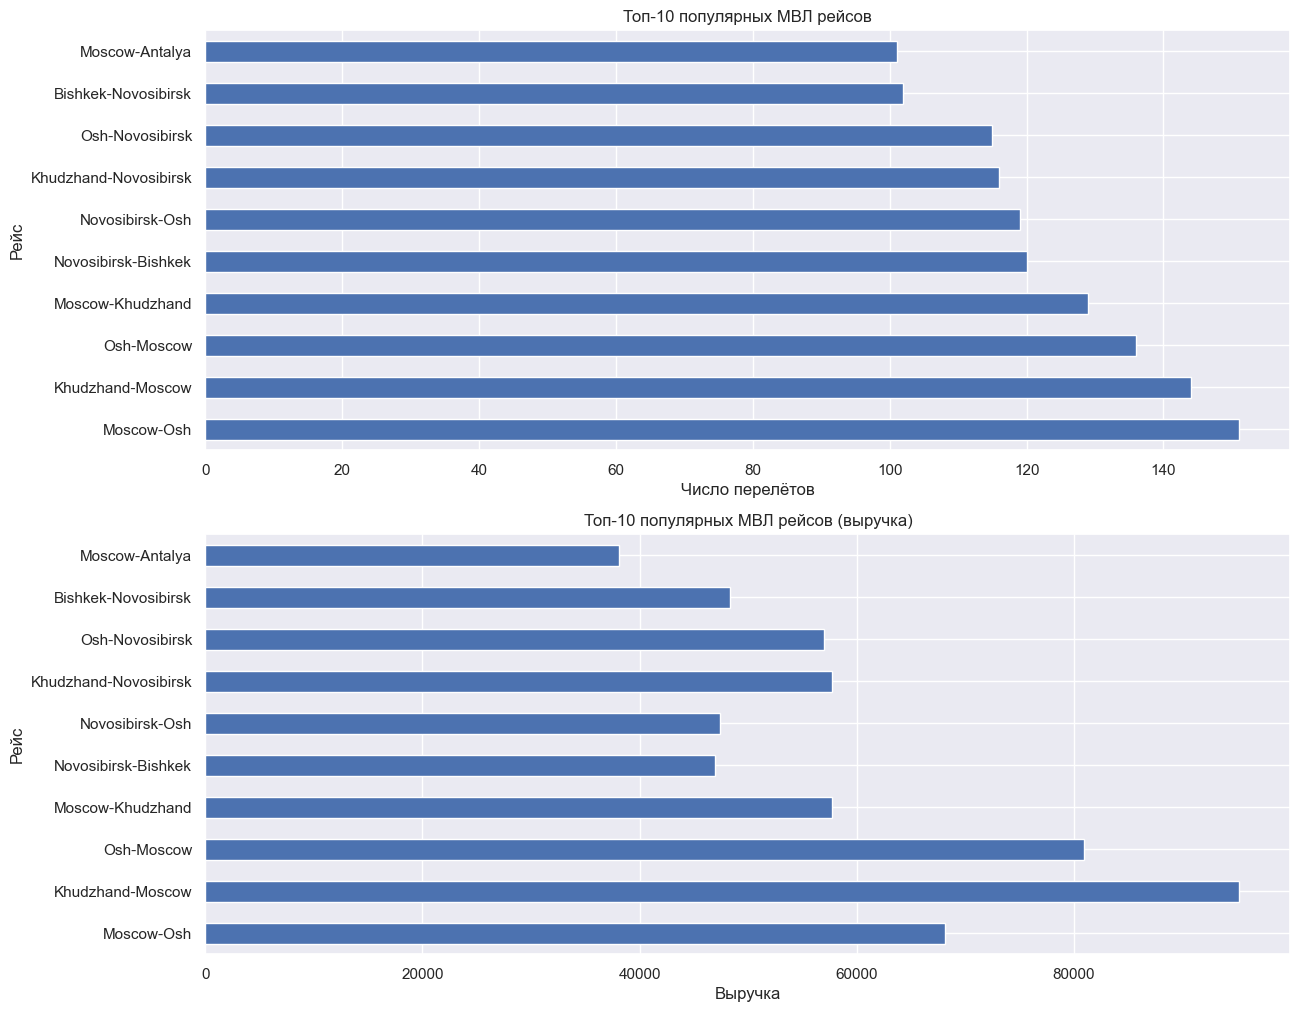

In [965]:
# отберём топ-10 рейсов МВЛ и визуализируем результат
top_10_mvl = df.query('flight_type == "МВЛ"').pivot_table(index='rout', aggfunc=['sum', 'count'], values='revenue').reset_index()
top_10_mvl.columns = ['rout', 'sum', 'count']
top_10_mvl = top_10_mvl.sort_values(by='count', ascending=False).head(10)
print(top_10_mvl)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 12))
top_10_mvl.plot(kind='barh',
               y = 'count',
               x = 'rout',
               # figsize = (14,7),
               ylabel = 'Рейс',
               xlabel = 'Число перелётов',
               title='Топ-10 популярных МВЛ рейсов',
               rot = 0,
               legend = False,
               ax=ax1)
top_10_mvl.plot(kind='barh',
               y = 'sum',
               x = 'rout',
               # figsize = (14,7),
               ylabel = 'Рейс',
               xlabel = 'Выручка',
               title='Топ-10 популярных МВЛ рейсов (выручка)',
               rot = 0,
               legend = False,
               ax=ax2)
plt.show()

На двух графиках представлены топ-10 международных рейсов по двум показателям: по количеству перелётов и по выручке. Видно, что лидирующие маршруты в обоих рейтингах почти совпадают — например, Moscow-Osh и Khudzhand-Moscow находятся на вершине как по числу продаж, так и по доходу. Это говорит о том, что спрос и доходность этих направлений тесно связаны — чем больше перелётов, тем выше выручка. Однако есть небольшие различия: например, маршрут Osh-Moscow занимает 2-е место по выручке, но только 4-е по количеству перелётов — это может указывать на более высокий средний чек или частые покупки бизнес-класса. Аналогично, Novosibirsk-Osh имеет высокое количество перелётов, но не такой высокий уровень выручки — возможно, здесь преобладают бюджетные тарифы.

                      rout     sum  count
256           Sochi-Moscow  513970   1326
138           Moscow-Sochi  480480   1292
260  St. Petersburg-Moscow  280870   1211
139  Moscow-St. Petersburg  273720   1190
192     Novosibirsk-Moscow  460720    967
125     Moscow-Novosibirsk  440440    944
52            Kazan-Moscow  205230    759
107           Moscow-Kazan  204660    757
143             Moscow-Ufa  210610    708
209      Novosibirsk-Sochi  382470    668


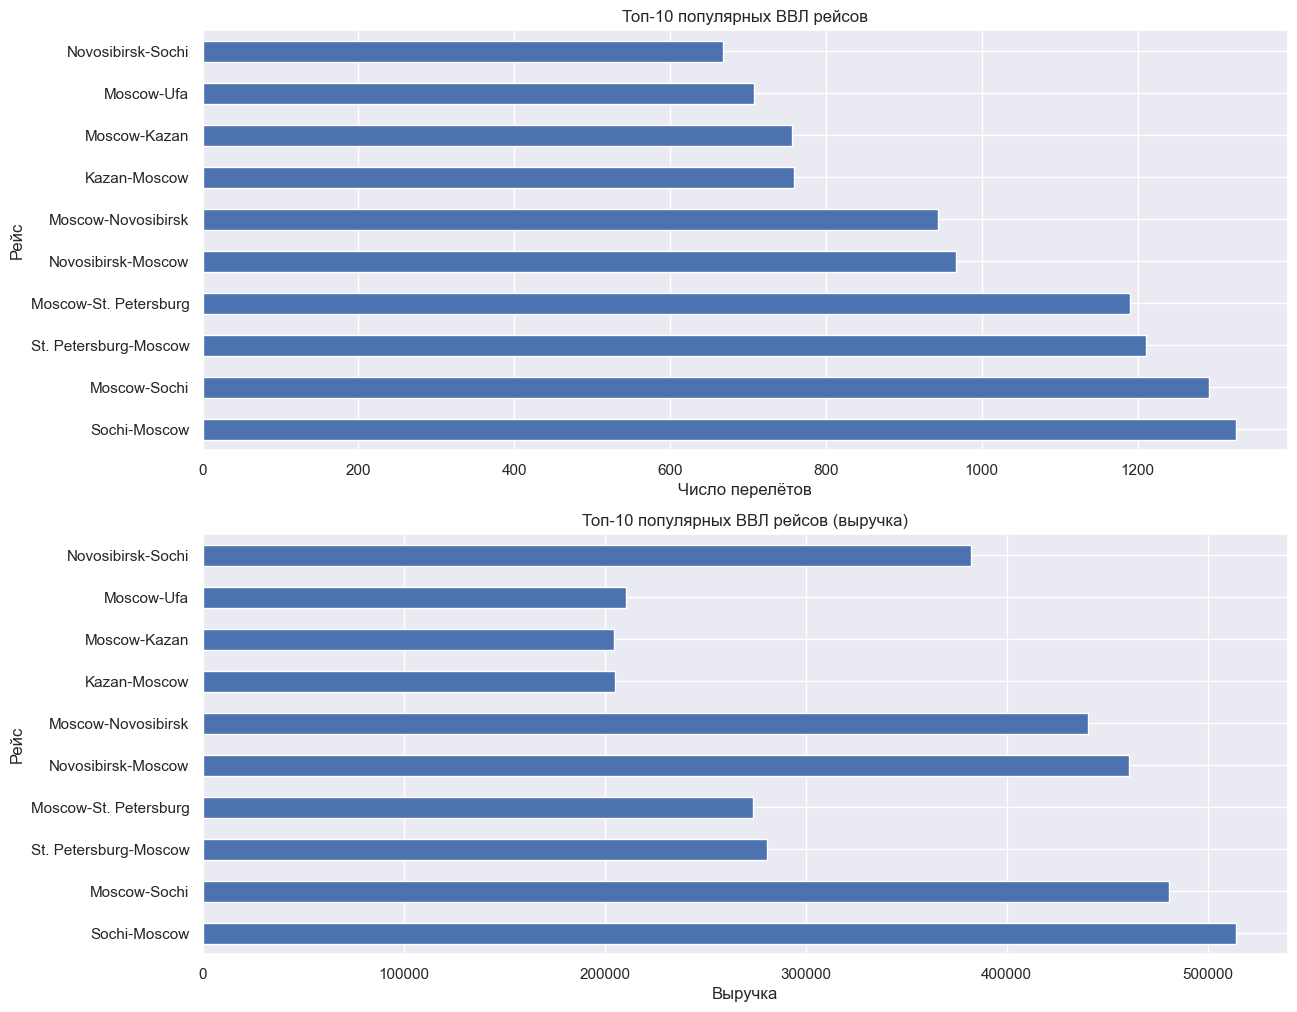

In [966]:
# отберём топ-10 рейсов ВВЛ и визуализируем результат
top_10_mvl = df.query('flight_type == "ВВЛ"').pivot_table(index='rout', aggfunc=['sum', 'count'], values='revenue').reset_index()
top_10_mvl.columns = ['rout', 'sum', 'count']
top_10_mvl = top_10_mvl.sort_values(by='count', ascending=False).head(10)
print(top_10_mvl)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 12))
top_10_mvl.plot(kind='barh',
               y = 'count',
               x = 'rout',
               # figsize = (14,7),
               ylabel = 'Рейс',
               xlabel = 'Число перелётов',
               title='Топ-10 популярных ВВЛ рейсов',
               rot = 0,
               legend = False,
               ax=ax1)
top_10_mvl.plot(kind='barh',
               y = 'sum',
               x = 'rout',
               # figsize = (14,7),
               ylabel = 'Рейс',
               xlabel = 'Выручка',
               title='Топ-10 популярных ВВЛ рейсов (выручка)',
               rot = 0,
               legend = False,
               ax=ax2)
plt.show()

На графиках представлены топ-10 внутренних рейсов по двум ключевым показателям — по количеству перелётов и по выручке. Видно, что лидерами по популярности являются маршруты с Москвой: Sochi-Moscow и Moscow-Sochi занимают первые места по числу продаж, а также входят в топ-3 по выручке. Это говорит о высокой востребованности направлений между столицей и курортами, особенно в летний сезон. Интересно, что Novosibirsk-Sochi — один из самых доходных маршрутов, несмотря на меньшее количество перелётов (668), что указывает на более высокий средний чек — возможно, здесь чаще летают бизнес-пассажиры или используются премиальные тарифы. Также заметно, что Moscow-St. Petersburg — один из самых загруженных маршрутов, но по выручке он уступает Sochi-Moscow, что может говорить о более низкой цене билетов на этом направлении. Вывод: для оптимизации прибыли стоит сосредоточиться на маршрутах с высокой загрузкой и хорошей доходностью — таких как Sochi-Moscow, Moscow-Sochi и Novosibirsk-Sochi. Также важно анализировать маршруты с высокой выручкой при меньшем объёме — они могут быть менее массовыми, но более прибыльными, и их стоит поддерживать специальными предложениями или акциями.

### Определение зависимости выручки от других признаков

Определите есть ли зависимость выручки от других признаков. Постройте матрицу корреляций.

In [967]:
df.head(1)

,issue_date,flight_date,pax_type,revenue,orig_city_code,dest_city_code,flight_type,ffp_flag,sale_type,season_sales,season_flights,date_diff,date_diff_name,orig_city,dest_city,rout
0,2021-12-07,2022-01-11,AD,200,MOW,KGD,ВВЛ,False,ONLINE,Зима,Зима,35,рано,Moscow,Kaliningrad,Moscow-Kaliningrad


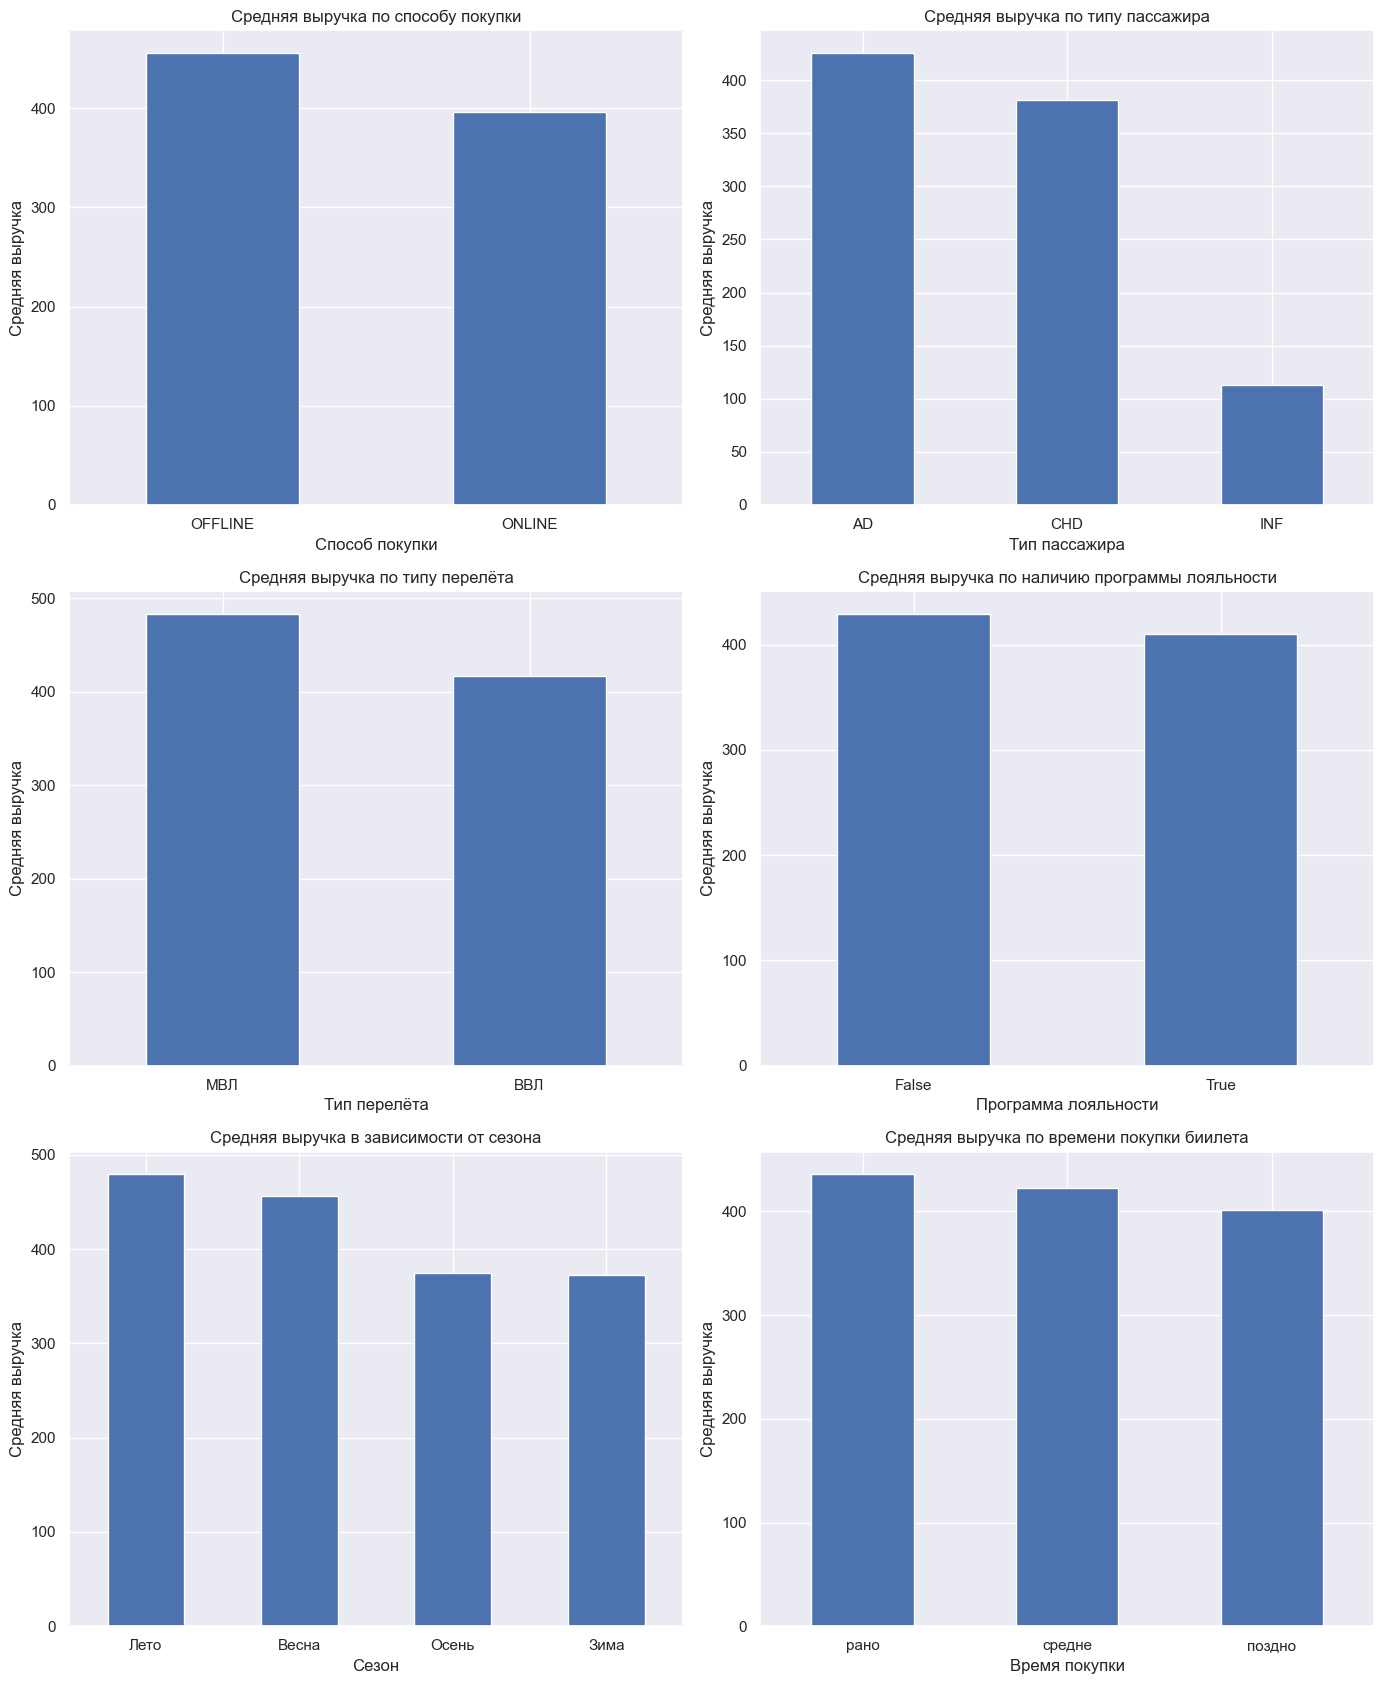

In [968]:
fig, ((ax1, ax2), (ax3, ax4), (ax5, ax6)) = plt.subplots(3, 2, figsize=(14, 17))

# 1. Способ покупки
df.groupby('sale_type')['revenue'].mean().sort_values(ascending=False).plot(
    kind='bar', ax=ax1, rot=0, legend=False
)
ax1.set_title('Средняя выручка по способу покупки')
ax1.set_xlabel('Способ покупки')
ax1.set_ylabel('Средняя выручка')

# 2. Тип пассажира
df.groupby('pax_type')['revenue'].mean().sort_values(ascending=False).plot(
    kind='bar', ax=ax2, rot=0, legend=False
)
ax2.set_title('Средняя выручка по типу пассажира')
ax2.set_xlabel('Тип пассажира')
ax2.set_ylabel('Средняя выручка')

# 3. Тип перелёта
df.groupby('flight_type')['revenue'].mean().sort_values(ascending=False).plot(
    kind='bar', ax=ax3, rot=0, legend=False
)
ax3.set_title('Средняя выручка по типу перелёта')
ax3.set_xlabel('Тип перелёта')
ax3.set_ylabel('Средняя выручка')

# 4. Программа лояльности
df.groupby('ffp_flag')['revenue'].mean().sort_values(ascending=False).plot(
    kind='bar', ax=ax4, rot=0, legend=False
)
ax4.set_title('Средняя выручка по наличию программы лояльности')
ax4.set_xlabel('Программа лояльности')
ax4.set_ylabel('Средняя выручка')

# 5. Сезон
df.groupby('season_sales')['revenue'].mean().sort_values(ascending=False).plot(
    kind='bar', ax=ax5, rot=0, legend=False
)
ax5.set_title('Средняя выручка в зависимости от сезона')
ax5.set_xlabel('Сезон')
ax5.set_ylabel('Средняя выручка')

# 6. Время покупки билета
df.groupby('date_diff_name')['revenue'].mean().sort_values(ascending=False).plot(
    kind='bar', ax=ax6, rot=0, legend=False
)
ax6.set_title('Средняя выручка по времени покупки биилета')
ax6.set_xlabel('Время покупки')
ax6.set_ylabel('Средняя выручка')

plt.tight_layout()
plt.show()

На графиках показано, как средняя выручка варьируется в зависимости от разных факторов. Видно, что офлайн-покупатели тратят в среднем больше — около 450 единиц против 400 у онлайн-клиентов, что подтверждает их склонность к более дорогим билетам или дополнительным услугам. Среди пассажиров взрослые (AD) приносят наибольшую среднюю выручку — почти 420, тогда как дети (CHD) и неизвестные (INF) — значительно меньше. По типу перелёта — МВЛ (международные) дают чуть большую среднюю выручку (~480) по сравнению с ВВЛ (~410), что логично из-за более высоких тарифов. Участники программы лояльности (True) тратят почти столько же, сколько и остальные — около 410 против 430, что говорит о том, что программа не снижает средний чек, а скорее стимулирует повторные покупки. По сезонам — летом и весной средняя выручка выше (~470–460), осенью и зимой — ниже (~370–380). Наконец, по времени покупки: ранние покупатели тратят немного больше (~440), чем те, кто покупает в последний момент (~410), хотя разница невелика.

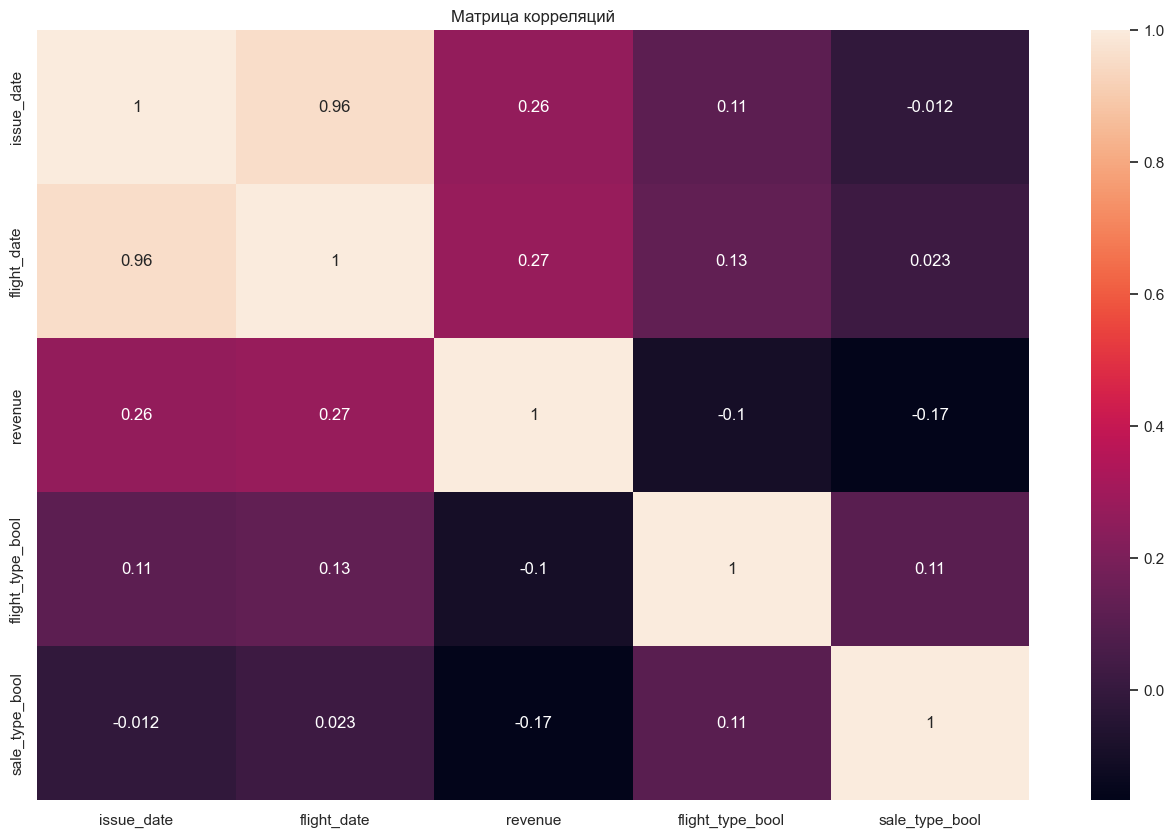

In [969]:
# для проверки корреляции переведем категориальные переменные в булевый тип, добавив новые столбцы
flight_type = {'ВВЛ': 1, 'МВЛ': 0}
df['flight_type_bool'] = df['flight_type'].map(flight_type)

sale_type = {'ONLINE': 1, 'OFFLINE': 0}
df['sale_type_bool'] = df['sale_type'].map(sale_type)

# построим матрицу корреляций
columns = ['issue_date', 'flight_date', 'revenue', 'flight_type_bool','sale_type_bool']
corr_bool = df[columns].corr()
plt.figure(figsize=(16, 10))
sns.heatmap(corr_bool, annot=True)
plt.title('Матрица корреляций')
plt.show()

На матрице корреляций видно, что единственные сильные линейные связи — между issue_date и flight_date (корреляция 0.96), что логично: дата покупки и дата вылета часто близки во времени. Остальные признаки демонстрируют очень слабую или отсутствующую линейную зависимость с выручкой и между собой. Например, корреляция revenue с issue_date и flight_date — всего 0.26–0.27, а с булевыми переменными (flight_type_bool, sale_type_bool) — даже отрицательная или близкая к нулю. Это означает, что выручка практически не зависит линейно от этих факторов — либо связь нелинейная, либо её нет вовсе.

### Вывод

Анализ данных о продаже авиабилетов позволил выявить ключевые закономерности, влияющие на выручку компании. Основной драйвер дохода — внутренние рейсы, которые значительно опережают международные по объёму выручки. При этом взрослые пассажиры формируют подавляющее большинство продаж, тогда как доля детских билетов и записей с неопределённым типом пассажира минимальна. Интересно, что клиенты, участвующие в программе лояльности, сохраняют средний чек на уровне остальной аудитории, что говорит о высокой эффективности программы — она не снижает доходность, а способствует удержанию клиентов.

Ярко выраженная сезонность подтверждена: пик продаж приходится на летние месяцы, а также на апрель–май и ноябрь — вероятно, из-за праздников и раннего бронирования зимних поездок. Зима и начало года остаются наименее активными периодами. Статистическая проверка показала, что выручка осенью и зимой действительно различается, что подчёркивает необходимость раздельного подхода к управлению спросом в эти сезоны. При этом между общей выручкой и количеством продаж наблюдается сильная положительная связь — рост дохода обусловлен в первую очередь увеличением числа продаж, а не ростом среднего чека.

Особое внимание заслуживает поведение клиентов по времени покупки. Контринтуитивно, но ранние покупатели тратят в среднем больше, чем те, кто бронирует в последний момент. Это может быть связано с тем, что планирующие заранее клиенты чаще выбирают премиальные тарифы или невозвратные билеты, в то время как спонтанные покупки приходятся на остаточные места по сниженным ценам. Гипотеза о различии выручки между группами подтверждена статистически.

Анализ маршрутов выявил, что топ-направления сосредоточены вокруг Москвы — как внутренних (Сочи, Санкт-Петербург), так и международных (Ош, Худжанд). Эти маршруты одновременно лидируют и по количеству продаж, и по выручке, что делает их стратегически важными. Наконец, попытка построить матрицу корреляций показала: линейная зависимость выручки от числовых признаков слаба, поскольку большинство факторов — категориальные. Это подтверждает необходимость анализа через группировку и визуализацию, а не через коэффициенты корреляции.